<a href="https://colab.research.google.com/github/iamnaymur/ml_meta_learning/blob/main/Updated_MetaLearning_ADSB_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ADS-B Message Injection Attacks — Few-Shot, Zero-Shot & Meta-Learning for Intrusion Detection

| Label | Attack type | Description |
|---|---|---|
| 0 | Legitimate | Authentic ADS-B messages, no attack |
| 1 | Path modification | Gradual manipulation of an aircraft's reported trajectory (lat/lon) |
| 2 | Ghost aircraft injection | A fabricated aircraft track injected into the airspace |
| 3 | Velocity drift | Gradual manipulation of an aircraft's reported speed |

## 0. Setup
Upload `Dataset.csv` when prompted (or mount Drive and edit the path).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

print("torch    :", torch.__version__)
print("numpy    :", np.__version__)
print("pandas   :", pd.__version__)
print("sklearn  :", sklearn.__version__)
print("seaborn  :", sns.__version__)

torch    : 2.11.0+cpu
numpy    : 2.1.3
pandas   : 2.2.3
sklearn  : 1.6.1
seaborn  : 0.13.2


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
DATA_PATH = '/content/drive/MyDrive/Machine learning/ADSB.csv'
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()


# df['onground'].value_counts()
# df['spi'].value_counts()

# icao24, callsign, time eigula

(22316, 18)


,time,icao24,lat,lon,velocity,heading,vertrate,callsign,onground,spi,squawk,baroaltitude,geoaltitude,lastposupdate,lastcontact,rss,doppler,label
0,1627918130,0c20b6,41.073349,-73.930298,194.919295,231.859760,0.0,CMP312,False,False,1364.0,10363.2,10675.62,1627918130,1627918130,-85.607674,588.045536,0
1,1627918140,0c20b6,41.062500,-73.948425,194.833737,231.647341,0.0,CMP312,False,False,1364.0,10363.2,10675.62,1627918140,1627918140,-85.601463,827.517243,0
2,1627918150,0c20b6,41.051393,-73.966952,195.153367,231.528897,0.0,CMP312,False,False,1364.0,10363.2,10675.62,1627918150,1627918150,-85.609035,774.034419,0
3,1627918160,0c20b6,41.040918,-73.984368,195.153367,231.528897,0.0,CMP312,False,False,1364.0,10363.2,10675.62,1627918160,1627918160,-85.631899,790.374778,0
4,1627918170,0c20b6,41.035418,-74.006463,195.237429,251.741020,0.0,CMP312,False,False,1364.0,10363.2,10675.62,1627918169,1627918170,-85.744771,-94.629770,1


## 1. Exploratory Data Analysis (EDA)



In [4]:
# print(df.dtypes)
# print("\nRows:", df.shape[0], " Columns:", df.shape[1])
print("\nUnique aircraft (icao24):", df['icao24'].nunique()) #TOTAL ase 275 ta
# print("Unique callsigns:", df['callsign'].nunique())
df.describe(include='all').T



Unique aircraft (icao24): 275


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
time,22316.0,NaN,NaN,NaN,1627917737.833393,767.623426,1627916410.0,1627917080.0,1627917730.0,1627918390.0,1627919100.0
icao24,22316,275,a03f24,270,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,21175.0,NaN,NaN,NaN,40.744705,0.19235,40.194831,40.632862,40.730654,40.859344,41.411196
lon,21175.0,NaN,NaN,NaN,-73.715271,0.318908,-74.604835,-73.966371,-73.709679,-73.429947,-73.013855
velocity,19098.0,NaN,NaN,NaN,116.274996,77.304061,0.0,56.843152,95.725989,168.391324,311.837095
heading,19098.0,NaN,NaN,NaN,183.395058,110.63831,0.0,71.81344,201.133151,280.629755,359.999982
vertrate,19098.0,NaN,NaN,NaN,1.697861,11.411867,-28.28544,-3.57632,0.0,5.404464,36.993437
callsign,22128,277,DAL419,270,NaN,NaN,NaN,NaN,NaN,NaN,NaN
onground,22316,2,False,16979,NaN,NaN,NaN,NaN,NaN,NaN,NaN
spi,22316,2,False,22315,NaN,NaN,NaN,NaN,NaN,NaN,NaN


/tmp/ipykernel_4885/533274066.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[label_names[i] for i in counts.index], y=counts.values, ax=ax, palette='viridis')


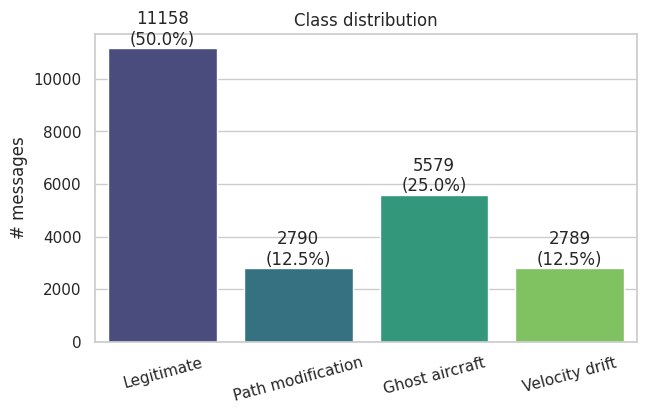

In [5]:
label_names = {0: 'Legitimate', 1: 'Path modification', 2: 'Ghost aircraft', 3: 'Velocity drift'}
counts = df['label'].value_counts().sort_index()

fig, ax = plt.subplots()
sns.barplot(x=[label_names[i] for i in counts.index], y=counts.values, ax=ax, palette='viridis')
ax.set_ylabel('# messages'); ax.set_title('Class distribution')
for i, v in enumerate(counts.values):
    ax.text(i, v + 150, f"{v}\n({v/len(df)*100:.1f}%)", ha='center')
plt.xticks(rotation=15)
plt.show()

/tmp/ipykernel_4885/2091000680.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_ylabel('Feature'); ax.set_yticklabels(missing.index, rotation=0)


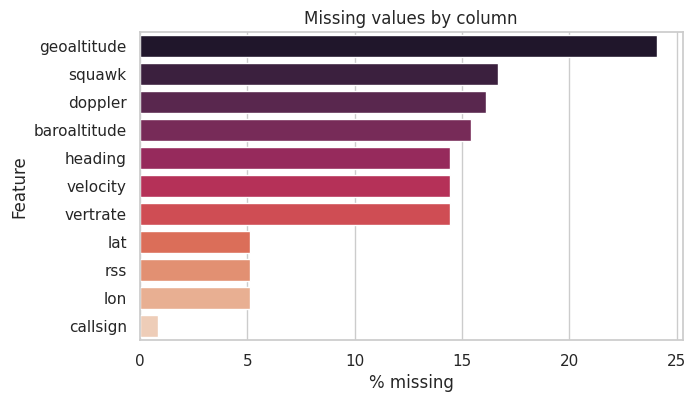

In [6]:
# --- Missing values overview ---
"""
This cell computes and visualizes the percentage of missing values per feature, filtering out any feature that has no missingness, so you can see at a glance which columns need imputation and how severe their gaps are.
"""
missing = df.isnull().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]

fig, ax = plt.subplots()
sns.barplot(x=missing.values, y=missing.index, ax=ax, hue=missing.index, palette='rocket', legend=False)
ax.set_xlabel('% missing'); ax.set_title('Missing values by column')
ax.set_ylabel('Feature'); ax.set_yticklabels(missing.index, rotation=0)
plt.show()

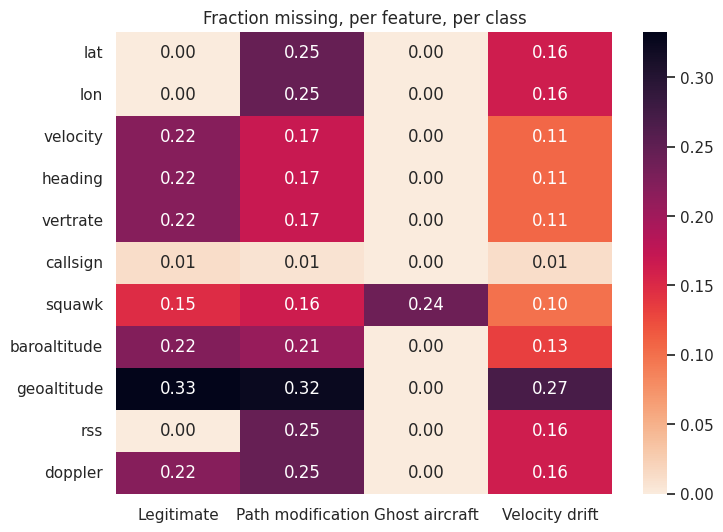

In [7]:
# --- IMPORTANT: missingness broken down BY CLASS ---

missing_by_label = (
    df.drop(columns=['label'])
      .isnull()
      .groupby(df['label'])
      .mean()
      .T
)
missing_by_label.columns = [label_names[c] for c in missing_by_label.columns]
missing_by_label = missing_by_label.loc[(missing_by_label.sum(axis=1) > 0)]

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(missing_by_label, annot=True, fmt='.2f', cmap='rocket_r', ax=ax)
ax.set_title('Fraction missing, per feature, per class')
plt.show()


Finding 1 -> for **every** feature, class `2` (ghost aircraft) has essentially
**0% missing values**, while classes `0`, `1` and `3` have 10–33% missingness on the same

In [8]:
# --- Does icao24 (aircraft identity) leak the label? ---
"""
1-> 179 means
179 aircrats appear with only one label accross all the rows.
mane 179 ta plane appear kore sudhumatro 1 ta label -> now this label can be 0, 1, 2, or 3
"""
leak_check = df.groupby('icao24')['label'].nunique().value_counts()
print("Number of DISTINCT labels seen per aircraft (icao24):")
print(leak_check)
print("\n->", (leak_check.index == 1).sum() and leak_check.loc[1] if 1 in leak_check.index else 0,
      "out of", df['icao24'].nunique(), "aircraft only ever appear under a single label.")


Number of DISTINCT labels seen per aircraft (icao24):
label
1    179
3     60
2     36
Name: count, dtype: int64

-> 179 out of 275 aircraft only ever appear under a single label.


Finding 2 —> Attack labels are tied to specific aircraft (icao24)


 Almost every `icao24` value maps to exactly **one** label. This makes sense given how the dataset was built (attacks were injected onto specific flights), but it means a **row-level random train/test split will leak the aircraft's identity across the split** — the model can partly memorize *which aircraft* is associated with *which attack*, rather than learning the general shape of the attack. We fix this below with a **group-aware split** (grouped by `icao24`), and we **exclude `icao24`/`callsign` as model features**.


/tmp/ipykernel_4885/388655103.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([label_names[i] for i in sorted(df['label'].unique())], rotation=20)
/tmp/ipykernel_4885/388655103.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([label_names[i] for i in sorted(df['label'].unique())], rotation=20)
/tmp/ipykernel_4885/388655103.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([label_names[i] for i in sorted(df['label'].unique())], rotation=20)
/tmp/ipykernel_4885/388655103.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([label_names[i] for i in sorted(df['label'].uniqu

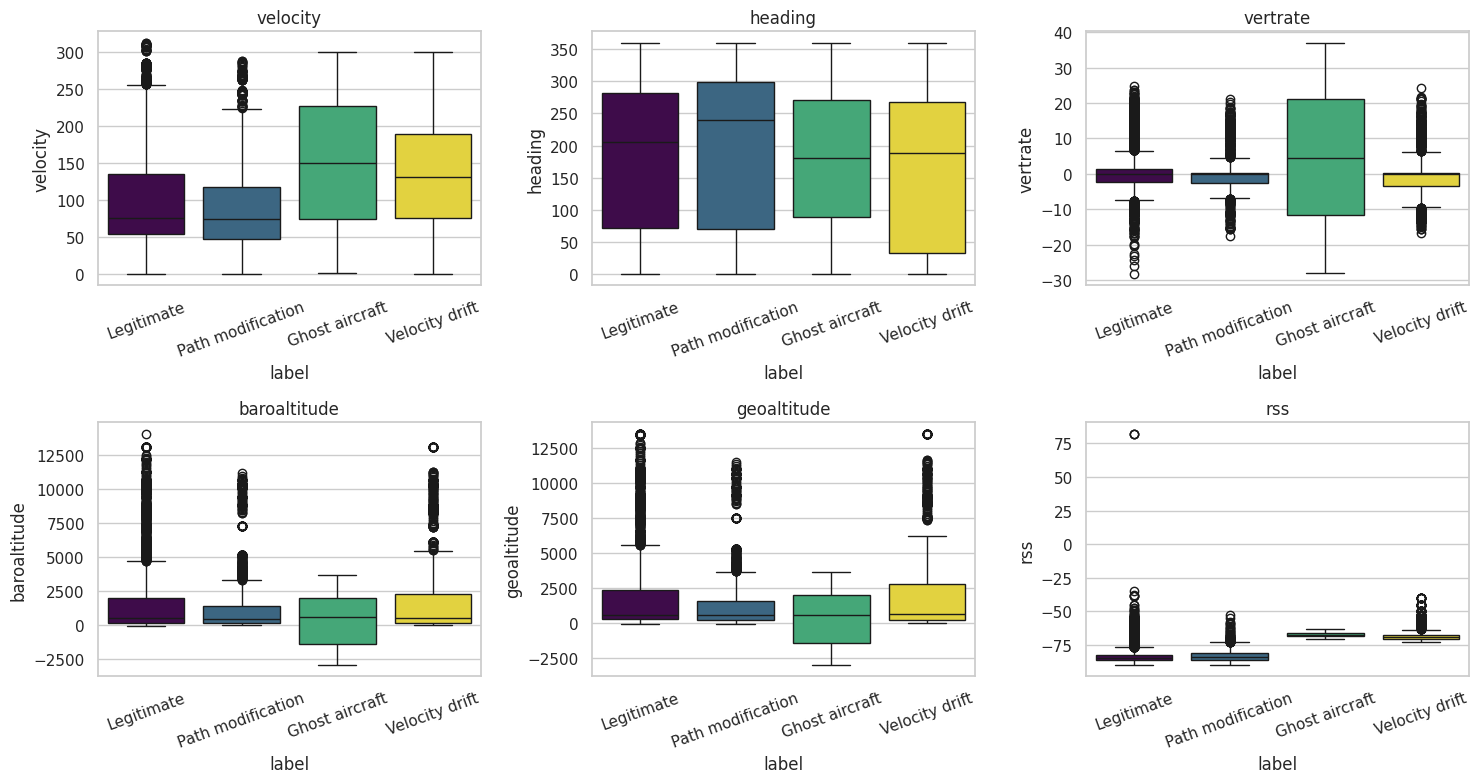

In [9]:
# --- Feature distributions per class (numeric features) ---
"""
in the total aircraft 276
179 aircraft appear with label 1, taile eita majority.
so this can create a problem, and the model starts memorizing the labels instead of generalizing and this is called IDENTITY LEAKAGE
"""


"""
we know the labels are leaky via identity; now let's look at whether the features themselves are informative with num_feats
"""
num_feats = ['velocity', 'heading', 'vertrate', 'baroaltitude', 'geoaltitude', 'rss']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.ravel(), num_feats):
    sns.boxplot(
        data=df, x='label', y=feat, ax=ax,
        hue='label',
        palette='viridis',
        legend=False
    )
    ax.set_xticklabels([label_names[i] for i in sorted(df['label'].unique())], rotation=20)
    ax.set_title(feat)
plt.tight_layout()
plt.show()


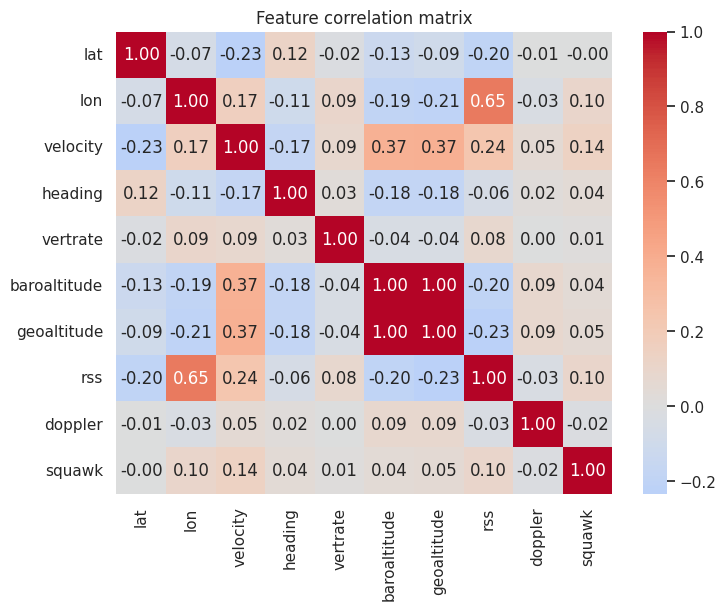

In [10]:
# --- Correlation heatmap (numeric features) ---
"""
well i havent dropped baroaltitude or geoaltitude.
These two in the correlation map shares exactly 1.00
I dont know if i should remove one now, im confused.


"""
corr_feats = ['lat','lon','velocity','heading','vertrate','baroaltitude','geoaltitude','rss','doppler','squawk']
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(df[corr_feats].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Feature correlation matrix')
plt.show()


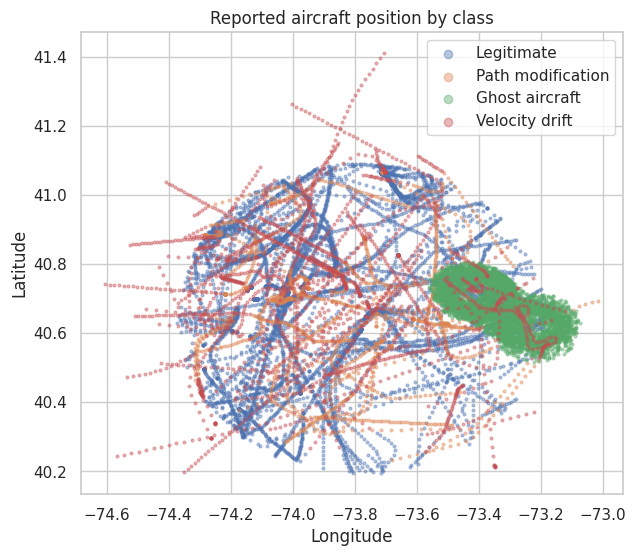

In [11]:
# --- Geospatial view: where do attacks show up? ---
fig, ax = plt.subplots(figsize=(7,6))
for lbl, color in zip([0,1,2,3], ['#4c72b0','#dd8452','#55a868','#c44e52']):
    sub = df[df['label']==lbl]
    ax.scatter(sub['lon'], sub['lat'], s=4, alpha=0.4, label=label_names[lbl], color=color)
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.legend(markerscale=3)
ax.set_title('Reported aircraft position by class')
plt.show()


## 2. Data Preprocessing and Leakage Prevention


Drop identifier / non-generalizable columns (`icao24`, `callsign` as features; raw epoch
   timestamps `time`, `lastposupdate`, `lastcontact`).

and then , Cast booleans (`onground`, `spi`) to integers.

Median-impute missing numeric values per column.

Standardize features (fit on train only).

Split with `GroupShuffleSplit` on `icao24` so no aircraft appears in both train and test. This split here is new for me with groupshufflesplit



In [12]:
from sklearn.impute import SimpleImputer

"""
i was calculating medians using the entire dataset, including test data. This causes preprocessing leakage.
Now i have handled missing values after splitting.
"""

FEATURE_COLS = [
    'lat', 'lon', 'velocity', 'heading',
    'vertrate', 'onground', 'spi',
    'squawk', 'baroaltitude',
    'geoaltitude', 'rss', 'doppler'
]

SEEN_CLASSES = [0, 1, 2]
NOVEL_CLASS = 3

data = df.copy()

data['onground'] = data['onground'].astype(int)
data['spi'] = data['spi'].astype(int)

# Keep missing values for now
X_raw = data[FEATURE_COLS].copy()

y = data['label'].to_numpy()

# Aircraft ID is only used for grouping
groups = data['icao24'].astype(str).to_numpy()

X = X_raw

print("Missing values:", X_raw.isna().sum().sum())
print("Dataset shape:", X_raw.shape)

X_raw.head()

Missing values: 29200
Dataset shape: (22316, 12)


,lat,lon,velocity,heading,vertrate,onground,spi,squawk,baroaltitude,geoaltitude,rss,doppler
0,41.073349,-73.930298,194.919295,231.859760,0.0,0,0,1364.0,10363.2,10675.62,-85.607674,588.045536
1,41.062500,-73.948425,194.833737,231.647341,0.0,0,0,1364.0,10363.2,10675.62,-85.601463,827.517243
2,41.051393,-73.966952,195.153367,231.528897,0.0,0,0,1364.0,10363.2,10675.62,-85.609035,774.034419
3,41.040918,-73.984368,195.153367,231.528897,0.0,0,0,1364.0,10363.2,10675.62,-85.631899,790.374778
4,41.035418,-74.006463,195.237429,251.741020,0.0,0,0,1364.0,10363.2,10675.62,-85.744771,-94.629770


In [13]:
"""
my current experiment holds out class 3 (velocity drift) as an unseen attack.
So the model should not learn preprocessing statistics from that class during training.
i stiill transform class 3 using the already-fitted imputer and scaler, but it does not influence their fitted values.
"""

# STEP 1: Split by aircraft ID

outer = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

trainval_idx, test_idx = next(
    outer.split(X_raw, y, groups=groups)
)

# STEP 2: Create validation set

inner = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=SEED + 1
)

tr_rel, va_rel = next(
    inner.split(
        X_raw.iloc[trainval_idx],
        y[trainval_idx],
        groups=groups[trainval_idx]
    )
)

train_idx = trainval_idx[tr_rel]
val_idx = trainval_idx[va_rel]


# STEP 3: Create raw partitions

X_train_df = X_raw.iloc[train_idx].copy()
X_val_df = X_raw.iloc[val_idx].copy()
X_test_df = X_raw.iloc[test_idx].copy()

y_train = y[train_idx]
y_val = y[val_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]
groups_val = groups[val_idx]
groups_test = groups[test_idx]


# STEP 4: Check aircraft overlap

assert len(set(groups_train) & set(groups_val)) == 0
assert len(set(groups_train) & set(groups_test)) == 0
assert len(set(groups_val) & set(groups_test)) == 0

print("No aircraft overlap found!")


# STEP 5: Select seen-class training samples

seen_train_mask = np.isin(y_train, SEEN_CLASSES)


# STEP 6: Fit imputer on seen training samples ONLY

imputer = SimpleImputer(
    strategy='median',
    keep_empty_features=True
)

imputer.fit(X_train_df.loc[seen_train_mask])

X_train_imputed = imputer.transform(X_train_df)
X_val_imputed = imputer.transform(X_val_df)
X_test_imputed = imputer.transform(X_test_df)


# STEP 7: Fit scaler on seen training samples ONLY

scaler = StandardScaler()

scaler.fit(X_train_imputed[seen_train_mask])

X_train = scaler.transform(
    X_train_imputed
).astype(np.float32)

X_val = scaler.transform(
    X_val_imputed
).astype(np.float32)

X_test = scaler.transform(
    X_test_imputed
).astype(np.float32)


# STEP 8: Check results

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("Train classes:", np.unique(y_train))
print("Validation classes:", np.unique(y_val))
print("Test classes:", np.unique(y_test))



No aircraft overlap found!
Train: (13358, 12)
Validation: (4691, 12)
Test: (4267, 12)
Train classes: [0 1 2 3]
Validation classes: [0 1 2 3]
Test classes: [0 1 2 3]


In [14]:
# # Convert scaled X_train back to dataframe
# # lastposupdate and lastContact can be used for new engineered features, but not direclty as they are huge stamps.

X_train_scaled_df = pd.DataFrame(
    X_train,
    columns=FEATURE_COLS
)

X_train_scaled_df.head()


,lat,lon,velocity,heading,vertrate,onground,spi,squawk,baroaltitude,geoaltitude,rss,doppler
0,-0.634343,1.338820,0.848253,0.905494,-0.174452,-0.60613,-0.009164,0.54218,0.064015,0.052179,1.413132,-0.452195
1,-0.919745,1.497141,-1.301711,0.089583,1.104078,-0.60613,-0.009164,0.54218,-1.367262,-1.409696,1.597838,-0.259448
2,-1.103307,1.514327,-1.512713,-0.074114,1.095013,-0.60613,-0.009164,0.54218,0.760050,0.746612,1.343500,-0.719020
3,-0.543970,1.255002,-1.177619,1.100515,1.567841,-0.60613,-0.009164,0.54218,0.051710,0.034573,1.299510,-0.317242
4,-0.370245,1.355861,-0.985088,1.431435,-1.736666,-0.60613,-0.009164,0.54218,-1.411417,-1.459069,1.320329,0.466435


In [15]:

print("After StandardScaler:")

print("\nTrain mean (first 5 features):")
print(X_train.mean(axis=0)[:5])

print("\nTrain std (first 5 features):")
print(X_train.std(axis=0)[:5])


print("\nValidation mean (first 5 features):")
print(X_val.mean(axis=0)[:5])


print("\nTest mean (first 5 features):")
print(X_test.mean(axis=0)[:5])

After StandardScaler:

Train mean (first 5 features):
[-0.01718602 -0.05695052  0.04666892 -0.01680068 -0.02711887]

Train std (first 5 features):
[0.98997283 1.0049593  1.0095713  1.0067463  0.9605955 ]

Validation mean (first 5 features):
[-0.08990423  0.1242545   0.11132931  0.06384894 -0.04340475]

Test mean (first 5 features):
[-0.14007612 -0.25280604 -0.09019258 -0.23588452 -0.04658781]


In [16]:
print("Aircraft overlap checks:")

print(
    "Train vs Validation:",
    len(set(groups_train) & set(groups_val))
)

print(
    "Train vs Test:",
    len(set(groups_train) & set(groups_test))
)

print(
    "Validation vs Test:",
    len(set(groups_val) & set(groups_test))
)

print("\nMissing values after preprocessing:")

print("Train:", np.isnan(X_train).sum())
print("Validation:", np.isnan(X_val).sum())
print("Test:", np.isnan(X_test).sum())


print('\n')
print("After imputation:")
print("Train:", np.isnan(X_train_imputed).sum())
print("Validation:", np.isnan(X_val_imputed).sum())
print("Test:", np.isnan(X_test_imputed).sum())

print('\n')
print("\nAfter scaling:")
print("Train:", np.isnan(X_train).sum())
print("Validation:", np.isnan(X_val).sum())
print("Test:", np.isnan(X_test).sum())

Aircraft overlap checks:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

Missing values after preprocessing:
Train: 0
Validation: 0
Test: 0


After imputation:
Train: 0
Validation: 0
Test: 0



After scaling:
Train: 0
Validation: 0
Test: 0


In [17]:
class_distribution = pd.DataFrame({
    "Train": pd.Series(y_train).value_counts(),
    "Validation": pd.Series(y_val).value_counts(),
    "Test": pd.Series(y_test).value_counts()
}).fillna(0).astype(int)

print(class_distribution.sort_index())

   Train  Validation  Test
0   6858        1718  2582
1   1609         663   518
2   3443        1602   534
3   1448         708   633


In [18]:
# Count unique aircraft for each class in each split

for name, labels, aircraft in [
    ("Train", y_train, groups_train),
    ("Validation", y_val, groups_val),
    ("Test", y_test, groups_test)
]:
    print(f"\n{name} - Unique aircraft per class")

    for cls in sorted(np.unique(labels)):
        count = len(np.unique(aircraft[labels == cls]))
        print(f"Class {cls}: {count} aircraft")


Train - Unique aircraft per class
Class 0: 151 aircraft
Class 1: 35 aircraft
Class 2: 14 aircraft
Class 3: 56 aircraft

Validation - Unique aircraft per class
Class 0: 49 aircraft
Class 1: 13 aircraft
Class 2: 6 aircraft
Class 3: 22 aircraft

Test - Unique aircraft per class
Class 0: 53 aircraft
Class 1: 12 aircraft
Class 2: 2 aircraft
Class 3: 18 aircraft


In [19]:
# Check aircraft diversity for the novel class
novel_mask = (y_test == NOVEL_CLASS)

aircraft_counts = pd.Series(
    groups_test[novel_mask]
).value_counts()

print("Novel-class aircraft:", len(aircraft_counts))
print("Minimum messages:", aircraft_counts.min())
print("Maximum messages:", aircraft_counts.max())
print("Median messages:", aircraft_counts.median())

print("\nMessages per aircraft:")
print(aircraft_counts.to_string())

Novel-class aircraft: 18
Minimum messages: 5
Maximum messages: 148
Median messages: 23.0

Messages per aircraft:
a38d8d    148
a03f66     69
a24720     69
a1b877     50
a24e13     49
a37ae4     39
a11d47     27
4c0221     24
a2e82a     24
a116e8     22
899104     21
a091d5     20
a2b060     17
a1e0a7     16
a20028     14
a059e3     10
a02a3f      9
a060ae      5


### 2.1 Quantifying Leakage: Naive Split vs Group-Aware Split

To make Finding #2 concrete, here's the same Random Forest baseline trained/evaluated two ways.


In [20]:
# (a) Naive row-level random split — ignores that rows from the same aircraft can land on both sides
"""
naive split is the one we use most of the time, but altho the numbers for group-aware split is smaller than the naive. We will still use the group-aware from now on, karon hocche
lets understand the analogy->
naive split hocche, emon ekta student je emon question portese jeigulai exactly exam e asbe,
and on the other hand group-split hocche emon student je actual concepts bujhtese, so which one is better? Group-aware split right?

---------------------
To be more technical about this ->
Naive split (99%): The model can "see" the same aircraft in train and test, so it memorizes them. Looks great, means little.
Group split (86%): The model must classify unseen aircraft — like a real IDS will. Number is lower, but it's what you'll actually get in production.
Why choose the lower one? Because you'd rather know the truth (86%) than believe a lie (99%). The honest number tells you the model's actual capability and gives you something real to improve.



"""

# (a) Naive row-level random split
naive_train_idx, naive_test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.25,
    random_state=SEED,
    stratify=y
)

# Fit imputer ONLY on naive training data
naive_imp = SimpleImputer(
    strategy='median',
    keep_empty_features=True
)

Xtr_n = naive_imp.fit_transform(
    X_raw.iloc[naive_train_idx]
)

Xte_n = naive_imp.transform(
    X_raw.iloc[naive_test_idx]
)

ytr_n = y[naive_train_idx]
yte_n = y[naive_test_idx]

rf_naive = RandomForestClassifier(
    n_estimators=200,
    random_state=SEED,
    n_jobs=-1
)

rf_naive.fit(Xtr_n, ytr_n)
pred_naive = rf_naive.predict(Xte_n)


# (b) Group-aware split
rf_group = RandomForestClassifier(
    n_estimators=200,
    random_state=SEED,
    n_jobs=-1
)

rf_group.fit(X_train_imputed, y_train)
pred_group = rf_group.predict(X_test_imputed)


# (c) Compare results
naive_overlap = len(
    set(groups[naive_train_idx]) &
    set(groups[naive_test_idx])
)

print("Shared aircraft in naive split:", naive_overlap)

print(
    f"Naive random split -> "
    f"Accuracy: {accuracy_score(yte_n, pred_naive):.4f}, "
    f"Macro-F1: {f1_score(yte_n, pred_naive, average='macro'):.4f}"
)

print(
    f"Group-aware split -> "
    f"Accuracy: {accuracy_score(y_test, pred_group):.4f}, "
    f"Macro-F1: {f1_score(y_test, pred_group, average='macro'):.4f}"
)


Shared aircraft in naive split: 268
Naive random split -> Accuracy: 0.9900, Macro-F1: 0.9827
Group-aware split -> Accuracy: 0.8760, Macro-F1: 0.7866


## 3. ProtoNet Meta-Learning Framework


In [21]:
SEEN_CLASSES = [0, 1, 2]     # used during meta-training
NOVEL_CLASS  = 3 #this class the model will never see while training

"""
we filter the training set to only include rows, jeigulate 0,1,2, ase.
class 3 er row gula drop kore dibo.
thats the whole point of it, eikhane 3 number class ta ekta unknown attack er moto kaj korbe.

X_train_seen -> 0, 1, 2 eigula ache
X_test -> sobgulai ache , and eita untouched
"""
seen_mask_train = np.isin(y_train, SEEN_CLASSES)
X_train_seen, y_train_seen = X_train[seen_mask_train], y_train[seen_mask_train]

"""
This is just a small neural network
this 3 layes neural network that maps 12 dimentional into 32 dims. The raw features arent direclty useful for classification, so the encoder learns a better representation where distances are meaningful.

"""

class Encoder(nn.Module):
    """Small MLP embedding network f_theta."""
    def __init__(self, in_dim, hidden=64, out_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, out_dim),
        )
    def forward(self, x):
        return self.net(x)

"""
If meta-learning is "training to be good at learning new things quickly," then sample_episode is the flashcard generator — it keeps producing new flashcards so the student never sees the same problem twice.

Sample_episode is  like a mini-task every time its called. So every task is different and so the model cant memorize and forces to learn the generalization...
"""

def sample_episode(
    Xd, yd, classes, n_way,
    k_shot, k_query, rng=None
):
    """Create one N-way K-shot training episode."""

    if rng is None:
        rng = np.random.default_rng()

    sup_x, sup_y = [], []
    qry_x, qry_y = [], []

    chosen = rng.choice(
        classes,
        size=n_way,
        replace=False
    )

    for i, c in enumerate(chosen):

        idx = np.where(yd == c)[0]

        required = k_shot + k_query

        if len(idx) < required:
            raise ValueError(
                f"Class {c} needs {required} samples, "
                f"but has only {len(idx)}."
            )

        sel = rng.choice(
            idx,
            size=required,
            replace=False
        )

        sup_x.append(Xd[sel[:k_shot]])
        sup_y.extend([i] * k_shot)

        qry_x.append(Xd[sel[k_shot:]])
        qry_y.extend([i] * k_query)

    return (
        torch.tensor(
            np.concatenate(sup_x),
            dtype=torch.float32
        ),
        torch.tensor(sup_y, dtype=torch.long),
        torch.tensor(
            np.concatenate(qry_x),
            dtype=torch.float32
        ),
        torch.tensor(qry_y, dtype=torch.long)
    )
"""
A simple analogy to remember ->

Encoder -> The students brain
sample_episode -> the practice problem the teacher writes
prototypical_loss -> the teachers grading of the students answer

-------------------

It's the scoring function that tells the encoder "here's how wrong you were on this mini-task." The encoder gets updated based on this score

"""

def prototypical_loss(encoder, sup_x, sup_y, qry_x, qry_y, n_way):
    z_sup, z_qry = encoder(sup_x), encoder(qry_x)
    prototypes = torch.stack([z_sup[sup_y == c].mean(0) for c in range(n_way)])
    logits = -torch.cdist(z_qry, prototypes)          # negative distance = logit
    loss = F.cross_entropy(logits, qry_y)
    acc = (logits.argmax(1) == qry_y).float().mean().item()
    return loss, acc


Episode   50 | Train Acc: 0.800 | Val Acc: 0.750
Episode  100 | Train Acc: 0.778 | Val Acc: 0.720
Episode  150 | Train Acc: 0.822 | Val Acc: 0.758
Episode  200 | Train Acc: 0.822 | Val Acc: 0.772
Episode  250 | Train Acc: 0.956 | Val Acc: 0.763
Episode  300 | Train Acc: 0.844 | Val Acc: 0.786
Episode  350 | Train Acc: 0.911 | Val Acc: 0.790
Episode  400 | Train Acc: 0.911 | Val Acc: 0.782
Episode  450 | Train Acc: 0.956 | Val Acc: 0.816
Episode  500 | Train Acc: 0.867 | Val Acc: 0.788
Episode  550 | Train Acc: 0.933 | Val Acc: 0.807
Episode  600 | Train Acc: 0.956 | Val Acc: 0.813
Episode  650 | Train Acc: 0.933 | Val Acc: 0.797
Episode  700 | Train Acc: 0.911 | Val Acc: 0.803
Episode  750 | Train Acc: 0.978 | Val Acc: 0.787
Episode  800 | Train Acc: 0.933 | Val Acc: 0.786
Episode  850 | Train Acc: 0.956 | Val Acc: 0.799
Episode  900 | Train Acc: 0.956 | Val Acc: 0.801
Episode  950 | Train Acc: 0.933 | Val Acc: 0.805
Episode 1000 | Train Acc: 1.000 | Val Acc: 0.819
Episode 1050 | Train

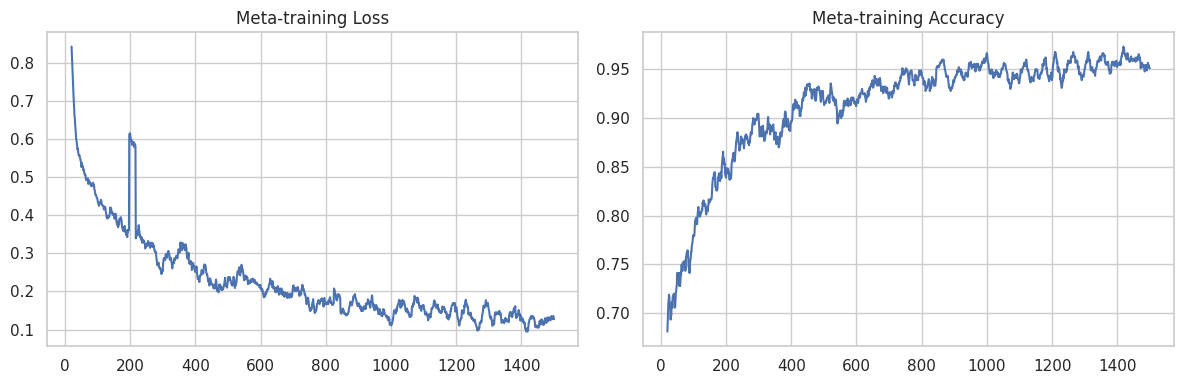

In [22]:
import copy

# Configuration
N_WAY = 3
K_SHOT_TRAIN = 5
K_QUERY_TRAIN = 15
N_EPISODES = 1500

# Keep only seen classes for validation
seen_mask_val = np.isin(y_val, SEEN_CLASSES)

X_val_seen = X_val[seen_mask_val]
y_val_seen = y_val[seen_mask_val]

# Original MLP baseline
torch.manual_seed(SEED)
encoder = Encoder(
    in_dim=X_train.shape[1],
    hidden=64,
    out_dim=32
)

# This optimizer was changed, altho not necesary
optimizer = torch.optim.AdamW(
    encoder.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

train_rng = np.random.default_rng(SEED)

history = []

best_val_acc = -1.0
best_state = None
best_episode = 0

# Meta-training
for ep in range(1, N_EPISODES + 1):

    encoder.train()

    sup_x, sup_y, qry_x, qry_y = sample_episode(
        X_train_seen,
        y_train_seen,
        SEEN_CLASSES,
        N_WAY,
        K_SHOT_TRAIN,
        K_QUERY_TRAIN,
        rng=train_rng
    )

    loss, acc = prototypical_loss(
        encoder,
        sup_x,
        sup_y,
        qry_x,
        qry_y,
        N_WAY
    )

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    history.append((ep, loss.item(), acc))

    # Validation every 100 episodes
    if ep % 50 == 0:

        encoder.eval()

        val_accs = []

        # Fixed validation episodes for fair
        # checkpoint comparison
        val_rng = np.random.default_rng(12345)

        with torch.no_grad():

            for _ in range(30):

                vs_x, vs_y, vq_x, vq_y = sample_episode(
                    X_val_seen,
                    y_val_seen,
                    SEEN_CLASSES,
                    N_WAY,
                    K_SHOT_TRAIN,
                    K_QUERY_TRAIN,
                    rng=val_rng
                )

                _, val_acc = prototypical_loss(
                    encoder,
                    vs_x,
                    vs_y,
                    vq_x,
                    vq_y,
                    N_WAY
                )

                val_accs.append(val_acc)

        mean_val_acc = np.mean(val_accs)

        print(
            f"Episode {ep:4d} | "
            f"Train Acc: {acc:.3f} | "
            f"Val Acc: {mean_val_acc:.3f}"
        )

        if mean_val_acc > best_val_acc:

            best_val_acc = mean_val_acc
            best_episode = ep

            best_state = copy.deepcopy(
                encoder.state_dict()
            )

# Restore best model
encoder.load_state_dict(best_state)
encoder.eval()

print("\nBest checkpoint:", best_episode)
print("Best validation accuracy:", round(best_val_acc, 4))

# Plot training history
hist_df = pd.DataFrame(
    history,
    columns=["episode", "loss", "acc"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    hist_df["episode"],
    hist_df["loss"].rolling(20).mean()
)
axes[0].set_title("Meta-training Loss")

axes[1].plot(
    hist_df["episode"],
    hist_df["acc"].rolling(20).mean()
)
axes[1].set_title("Meta-training Accuracy")

plt.tight_layout()
plt.show()

## 4. Few-Shot Learning Evaluation


In [23]:
from sklearn.metrics import recall_score

def few_shot_eval(
    encoder, X_data, y_data, group_data,
    seen_classes, novel_class, k_shot, seed=0
):
    rng = np.random.default_rng(seed)
    all_classes = list(seen_classes) + [novel_class]

    support_indices = []
    support_labels = []
    support_aircraft_set = set()

    # STEP 1: Select support samples
    for c in all_classes:

        class_idx = np.where(y_data == c)[0]

        aircraft, counts = np.unique(
            group_data[class_idx],
            return_counts=True
        )

        eligible = aircraft[counts >= k_shot]

        if len(eligible) == 0:
            raise ValueError(
                f"Class {c}: insufficient support samples"
            )

        chosen_aircraft = rng.choice(eligible)
        support_aircraft_set.add(chosen_aircraft)

        candidates = class_idx[
            group_data[class_idx] == chosen_aircraft
        ]

        selected = rng.choice(
            candidates, size=k_shot, replace=False
        )

        support_indices.extend(selected)
        support_labels.extend([c] * k_shot)

    # STEP 2: Globally exclude all support aircraft
    query_mask = (
        ~np.isin(group_data, list(support_aircraft_set))
        & np.isin(y_data, all_classes)
    )

    query_indices = np.where(query_mask)[0]

    support_indices = np.array(support_indices)
    query_y = y_data[query_indices]
    support_y = np.array(support_labels)

    if len(query_indices) == 0:
        raise ValueError("Query set is empty")

    if not set(all_classes).issubset(set(query_y)):
        raise ValueError("Some classes are missing from query set")

    # Verify aircraft independence
    assert set(
        group_data[support_indices]
    ).isdisjoint(set(group_data[query_indices]))

    # STEP 3: Generate embeddings
    encoder.eval()

    with torch.no_grad():

        z_support = encoder(
            torch.tensor(
                X_data[support_indices],
                dtype=torch.float32
            )
        )

        z_query = encoder(
            torch.tensor(
                X_data[query_indices],
                dtype=torch.float32
            )
        )

        # STEP 4: Calculate class prototypes
        prototypes = torch.stack([
            z_support[
                torch.tensor(support_y == c)
            ].mean(dim=0)
            for c in all_classes
        ])

        # STEP 5: Predict
        distances = torch.cdist(z_query, prototypes)

        pred_idx = distances.argmin(dim=1).numpy()
        predictions = np.array(all_classes)[pred_idx]

    return query_y, predictions


# Run repeated evaluation
results = []

for k in [1, 5, 10]:

    for seed in range(10):

        true, pred = few_shot_eval(
            encoder,
            X_test,
            y_test,
            groups_test,
            SEEN_CLASSES,
            NOVEL_CLASS,
            k_shot=k,
            seed=seed
        )

        results.append({
            "Shots": k,
            "Seed": seed,
            "Accuracy": accuracy_score(true, pred),
            "Macro_F1": f1_score(
                true, pred,
                average="macro",
                labels=[0, 1, 2, 3],
                zero_division=0
            ),
            "Novel_Recall": recall_score(
                true == NOVEL_CLASS,
                pred == NOVEL_CLASS,
                zero_division=0
            )
        })

results_df = pd.DataFrame(results)

summary = results_df.groupby("Shots")[
    ["Accuracy", "Macro_F1", "Novel_Recall"]
].agg(["mean", "std"])

print(summary.round(4))

      Accuracy         Macro_F1         Novel_Recall        
          mean     std     mean     std         mean     std
Shots                                                       
1       0.4280  0.1470   0.3930  0.0899       0.2510  0.2042
5       0.4028  0.1207   0.4189  0.0577       0.4025  0.2325
10      0.4855  0.1790   0.4511  0.0942       0.2812  0.2035


                   precision    recall  f1-score   support

       Legitimate      0.249     0.031     0.056      2489
Path modification      0.139     0.965     0.243       427
   Ghost aircraft      0.855     0.820     0.837       267
   Velocity drift      0.752     0.303     0.432       590

         accuracy                          0.235      3773
        macro avg      0.499     0.530     0.392      3773
     weighted avg      0.358     0.235     0.191      3773



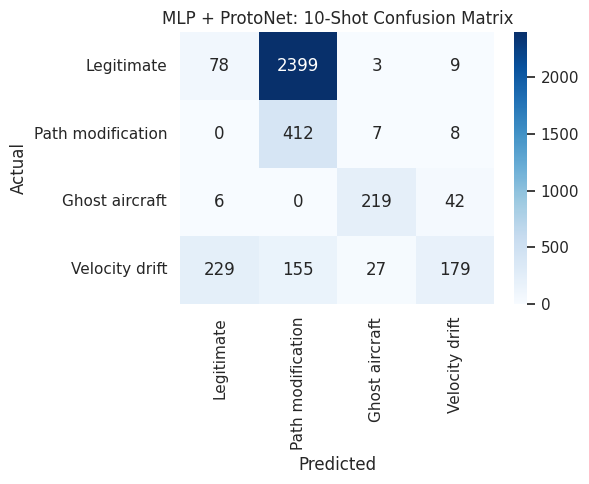

In [24]:
# Detailed report for 10-shot evaluation

true, pred = few_shot_eval(
    encoder,
    X_test,
    y_test,
    groups_test,
    SEEN_CLASSES,
    NOVEL_CLASS,
    k_shot=10,
    seed=1
)

print(
    classification_report(
        true,
        pred,
        labels=[0, 1, 2, 3],
        target_names=[
            label_names[c] for c in [0, 1, 2, 3]
        ],
        digits=3,
        zero_division=0
    )
)

cm = confusion_matrix(
    true,
    pred,
    labels=[0, 1, 2, 3]
)

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        label_names[c] for c in [0, 1, 2, 3]
    ],
    yticklabels=[
        label_names[c] for c in [0, 1, 2, 3]
    ],
    ax=ax
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("MLP + ProtoNet: 10-Shot Confusion Matrix")

plt.tight_layout()
plt.show()

In [25]:
# Freeze evaluation configuration for all future models

EVAL_SHOTS = [1, 5, 10]
EVAL_SEEDS = list(range(10))

BASELINE_RESULTS = results_df.copy()

print("Baseline results saved in memory.")
print("Evaluation shots:", EVAL_SHOTS)
print("Evaluation seeds:", EVAL_SEEDS)

BASELINE_RESULTS.to_csv(
    "MLP_ProtoNet_Baseline.csv",
    index=False
)

print("Baseline results exported successfully!")

Baseline results saved in memory.
Evaluation shots: [1, 5, 10]
Evaluation seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Baseline results exported successfully!


## 5. Residual MLP and Tabular ResNet

In [26]:
"""
Residual MLp -> Adds shortcut connections to an MLP
Tabular resnt -> Uses residual blocks, normalization, and dropout to learn from tabular data
both converts 12 ads-b feature into 32 dimbentional embeddings, just like the original MLP
"""
# STEP 3.1 — Advanced Encoder Architectures

class ResidualBlock(nn.Module):
    def __init__(self, dim, dropout=0.1):
        super().__init__()

        self.block = nn.Sequential(
            nn.Linear(dim, dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dim, dim)
        )

    def forward(self, x):
        return F.relu(x + self.block(x))


class ResidualMLPEncoder(nn.Module):
    def __init__(self, in_dim, hidden=64, out_dim=32):
        super().__init__()

        self.input_layer = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU()
        )

        self.res_blocks = nn.Sequential(
            ResidualBlock(hidden),
            ResidualBlock(hidden)
        )

        self.output_layer = nn.Linear(hidden, out_dim)

    def forward(self, x):
        x = self.input_layer(x)
        x = self.res_blocks(x)
        return self.output_layer(x)


# Tabular ResNet — normalized residual blocks

class TabularResBlock(nn.Module):
    def __init__(self, dim, hidden_dim=128, dropout=0.1):
        super().__init__()

        self.block = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return x + self.block(x)


class TabularResNetEncoder(nn.Module):
    def __init__(self, in_dim, hidden=64, out_dim=32):
        super().__init__()

        self.input_layer = nn.Linear(in_dim, hidden)

        self.res_blocks = nn.Sequential(
            TabularResBlock(hidden),
            TabularResBlock(hidden)
        )

        self.final_norm = nn.LayerNorm(hidden)
        self.output_layer = nn.Linear(hidden, out_dim)

    def forward(self, x):
        x = self.input_layer(x)
        x = self.res_blocks(x)
        x = self.final_norm(x)
        return self.output_layer(x)


# Check output dimensions

dummy_input = torch.randn(8, X_train.shape[1])

for model_class in [ResidualMLPEncoder, TabularResNetEncoder]:
    model = model_class(in_dim=X_train.shape[1])
    output = model(dummy_input)

    assert output.shape == (8, 32)

    print(model_class.__name__, "Output:", output.shape)


ResidualMLPEncoder Output: torch.Size([8, 32])
TabularResNetEncoder Output: torch.Size([8, 32])


In [27]:
"""
i trained the MLP manually  using 1500-episode loop
Rather than writing that entire training loop again and again for every architecture, here below created a reusable function
Uses the same sample_episode() and prototypical_loss() functions that I already have above
"""
# STEP 3.2 — Reusable ProtoNet Meta-Training

def train_protonet(model, model_name, seed=42):

    # Same settings as original MLP baseline
    torch.manual_seed(seed)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=1e-3,
        weight_decay=1e-4
    )

    train_rng = np.random.default_rng(seed)

    history = []
    best_val_acc = -1.0
    best_state = None
    best_episode = 0
    patience = 5
    patience_counter = 0

    for ep in range(1, N_EPISODES + 1):

        model.train()

        sup_x, sup_y, qry_x, qry_y = sample_episode(
            X_train_seen,
            y_train_seen,
            SEEN_CLASSES,
            N_WAY,
            K_SHOT_TRAIN,
            K_QUERY_TRAIN,
            rng=train_rng
        )

        loss, acc = prototypical_loss(
            model,
            sup_x,
            sup_y,
            qry_x,
            qry_y,
            N_WAY
        )

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()



        history.append((ep, loss.item(), acc))

        # Validation every 100 episodes
        if ep % 50 == 0:

            model.eval()
            val_accs = []

            # Same validation episodes for every checkpoint
            val_rng = np.random.default_rng(12345)

            with torch.no_grad():

                for _ in range(30):

                    vs_x, vs_y, vq_x, vq_y = sample_episode(
                        X_val_seen,
                        y_val_seen,
                        SEEN_CLASSES,
                        N_WAY,
                        K_SHOT_TRAIN,
                        K_QUERY_TRAIN,
                        rng=val_rng
                    )

                    _, val_acc = prototypical_loss(
                        model,
                        vs_x,
                        vs_y,
                        vq_x,
                        vq_y,
                        N_WAY
                    )

                    val_accs.append(val_acc)

            mean_val_acc = float(np.mean(val_accs))

            print(
                f"{model_name} | Episode {ep:4d} | "
                f"Train Acc: {acc:.3f} | "
                f"Val Acc: {mean_val_acc:.3f}"
            )

            if mean_val_acc > best_val_acc:
                best_val_acc = mean_val_acc
                best_episode = ep
                best_state = copy.deepcopy(
                    model.state_dict()
                )

                # reset patience when validation improves
                patience_counter = 0
            else:
                patience_counter += 1

            if patience_counter >= patience:
                print(f"Early stopping at episode {ep}")
                break

    # Restore best checkpoint
    model.load_state_dict(best_state)
    model.eval()

    print(f"\n{model_name} training completed!")
    print("Best checkpoint:", best_episode)
    print("Best validation accuracy:", round(best_val_acc, 4))

    history_df = pd.DataFrame(
        history,
        columns=["Episode", "Loss", "Accuracy"]
    )

    return model, history_df, best_val_acc, best_episode


In [28]:
# Train Residual MLP and Tabular ResNet
# STEP 3.3 — Train Both Advanced Architectures

advanced_models = {}
training_histories = {}
validation_results = []

model_configs = {
    "Residual_MLP": ResidualMLPEncoder,
    "Tabular_ResNet": TabularResNetEncoder
}

for model_name, model_class in model_configs.items():

    print("\n" + "=" * 55)
    print("Training:", model_name)
    print("=" * 55)

    # Reproducible weight initialization
    torch.manual_seed(SEED)

    model = model_class(
        in_dim=X_train.shape[1],
        hidden=64,
        out_dim=32
    )

    # ProtoNet meta-training and validation
    trained_model, hist, val_acc, best_ep = train_protonet(
        model,
        model_name,
        seed=SEED
    )

    advanced_models[model_name] = trained_model
    training_histories[model_name] = hist

    validation_results.append({
        "Model": model_name,
        "Best_Episode": best_ep,
        "Validation_Accuracy": val_acc
    })

validation_df = pd.DataFrame(validation_results)

print("\nADVANCED MODEL VALIDATION SUMMARY")
print(validation_df.to_string(index=False))

# Save checkpoints and training history
for model_name, model in advanced_models.items():

    torch.save(
        model.state_dict(),
        f"{model_name}_ProtoNet.pth"
    )

    training_histories[model_name].to_csv(
        f"{model_name}_Training_History.csv",
        index=False
    )



Training: Residual_MLP
Residual_MLP | Episode   50 | Train Acc: 0.822 | Val Acc: 0.731
Residual_MLP | Episode  100 | Train Acc: 0.778 | Val Acc: 0.722
Residual_MLP | Episode  150 | Train Acc: 0.822 | Val Acc: 0.770
Residual_MLP | Episode  200 | Train Acc: 0.933 | Val Acc: 0.780
Residual_MLP | Episode  250 | Train Acc: 0.956 | Val Acc: 0.784
Residual_MLP | Episode  300 | Train Acc: 0.822 | Val Acc: 0.784
Residual_MLP | Episode  350 | Train Acc: 0.956 | Val Acc: 0.801
Residual_MLP | Episode  400 | Train Acc: 0.956 | Val Acc: 0.758
Residual_MLP | Episode  450 | Train Acc: 0.956 | Val Acc: 0.791
Residual_MLP | Episode  500 | Train Acc: 0.911 | Val Acc: 0.786
Residual_MLP | Episode  550 | Train Acc: 0.956 | Val Acc: 0.772
Residual_MLP | Episode  600 | Train Acc: 0.956 | Val Acc: 0.800
Early stopping at episode 600

Residual_MLP training completed!
Best checkpoint: 350
Best validation accuracy: 0.8007

Training: Tabular_ResNet
Tabular_ResNet | Episode   50 | Train Acc: 0.889 | Val Acc: 0.82

In [29]:
# Evaluate 1-shot, 5-shot and 10-shot performance
# comparing results against my saved original MLP baseline
# STEP 3.4 — Few-Shot Evaluation and Comparison

advanced_results = []

for model_name, model in advanced_models.items():

    print("\nEvaluating:", model_name)

    for k in EVAL_SHOTS:

        for seed in EVAL_SEEDS:

            true, pred = few_shot_eval(
                model,
                X_test,
                y_test,
                groups_test,
                SEEN_CLASSES,
                NOVEL_CLASS,
                k_shot=k,
                seed=seed
            )

            advanced_results.append({
                "Model": model_name,
                "Shots": k,
                "Seed": seed,
                "Accuracy": accuracy_score(true, pred),
                "Macro_F1": f1_score(
                    true, pred,
                    average="macro",
                    labels=[0, 1, 2, 3],
                    zero_division=0
                ),
                "Novel_Recall": recall_score(
                    true == NOVEL_CLASS,
                    pred == NOVEL_CLASS,
                    zero_division=0
                ),
                "Legitimate_Recall": recall_score(
                    true == 0,
                    pred == 0,
                    zero_division=0
                )
            })

advanced_results_df = pd.DataFrame(advanced_results)

# Add original MLP results
baseline_comparison = BASELINE_RESULTS.copy()
baseline_comparison["Model"] = "Original_MLP"

# Calculate legitimate recall for MLP baseline
baseline_normal_recall = {}

for k in EVAL_SHOTS:
    for seed in EVAL_SEEDS:

        true, pred = few_shot_eval(
            encoder,
            X_test,
            y_test,
            groups_test,
            SEEN_CLASSES,
            NOVEL_CLASS,
            k_shot=k,
            seed=seed
        )

        baseline_normal_recall[(k, seed)] = recall_score(
            true == 0,
            pred == 0,
            zero_division=0
        )

baseline_comparison["Legitimate_Recall"] = [
    baseline_normal_recall[(int(k), int(s))]
    for k, s in zip(
        baseline_comparison["Shots"],
        baseline_comparison["Seed"]
    )
]

# Combine all models
all_results = pd.concat(
    [baseline_comparison, advanced_results_df],
    ignore_index=True
)

metrics = [
    "Accuracy",
    "Macro_F1",
    "Novel_Recall",
    "Legitimate_Recall"
]

comparison_summary = (
    all_results
    .groupby(["Model", "Shots"])[metrics]
    .agg(["mean", "std"])
)

print("\nFINAL COMPARISON")
print(comparison_summary.round(4).to_string())

# Save results
all_results.to_csv(
    "ProtoNet_Three_Model_Comparison.csv",
    index=False
)

validation_df.to_csv(
    "Advanced_Model_Validation.csv",
    index=False
)

print("\nAll comparison results saved.")



Evaluating: Residual_MLP

Evaluating: Tabular_ResNet

FINAL COMPARISON
                     Accuracy         Macro_F1         Novel_Recall         Legitimate_Recall        
                         mean     std     mean     std         mean     std              mean     std
Model          Shots                                                                                 
Original_MLP   1       0.4280  0.1470   0.3930  0.0899       0.2510  0.2042            0.4071  0.2832
               5       0.4028  0.1207   0.4189  0.0577       0.4025  0.2325            0.3390  0.2202
               10      0.4855  0.1790   0.4511  0.0942       0.2812  0.2035            0.4819  0.2934
Residual_MLP   1       0.4287  0.1446   0.4245  0.0841       0.3110  0.2042            0.3929  0.2593
               5       0.4423  0.1563   0.4535  0.0787       0.4490  0.2227            0.3959  0.2615
               10      0.4690  0.1748   0.4566  0.0835       0.3297  0.1853            0.4498  0.2879
Tabular_Re

In [30]:
# Diagnostic: support examples from multiple aircraft
# Uses VALIDATION data only

def diverse_support_episode(
    X_data, y_data, groups_data,
    classes, k_shot, seed=0
):
    rng = np.random.default_rng(seed)

    support_idx = []
    chosen_aircraft = set()

    for c in classes:
        class_idx = np.where(y_data == c)[0]

        aircraft_ids = np.unique(groups_data[class_idx])
        aircraft_ids = [
            a for a in aircraft_ids
            if a not in chosen_aircraft
        ]

        if len(aircraft_ids) < 2:
            raise ValueError(
                f"Class {c}: insufficient aircraft diversity"
            )

        rng.shuffle(aircraft_ids)

        # Keep at least one aircraft for queries
        n_aircraft = min(k_shot, len(aircraft_ids) - 1)

        selected_aircraft = aircraft_ids[:n_aircraft]
        chosen_aircraft.update(selected_aircraft)

        selected_rows = []

        # First select one message per aircraft
        for a in selected_aircraft:
            candidates = class_idx[
                groups_data[class_idx] == a
            ]
            selected_rows.append(rng.choice(candidates))

        # Fill remaining shots from selected aircraft
        if len(selected_rows) < k_shot:
            candidates = class_idx[
                np.isin(groups_data[class_idx], selected_aircraft)
            ]

            remaining = np.setdiff1d(
                candidates, selected_rows
            )

            extra = rng.choice(
                remaining,
                size=k_shot - len(selected_rows),
                replace=False
            )
            selected_rows.extend(extra)

        support_idx.extend(selected_rows)

    support_idx = np.asarray(support_idx, dtype=int)

    query_idx = np.where(
        ~np.isin(groups_data, list(chosen_aircraft))
        & np.isin(y_data, classes)
    )[0]

    assert set(groups_data[support_idx]).isdisjoint(
        set(groups_data[query_idx])
    )

    if not set(classes).issubset(set(y_data[query_idx])):
        raise ValueError("Missing query class")

    return support_idx, query_idx

In [31]:
def evaluate_support_diversity(
    model, k_shot=10, seeds=range(20)
):
    records = []
    classes = SEEN_CLASSES

    model.eval()

    for seed in seeds:
        support_idx, query_idx = diverse_support_episode(
            X_val_seen,
            y_val_seen,
            groups_val[np.isin(y_val, SEEN_CLASSES)],
            classes,
            k_shot,
            seed
        )

        with torch.no_grad():
            zs = model(torch.tensor(
                X_val_seen[support_idx],
                dtype=torch.float32
            ))

            zq = model(torch.tensor(
                X_val_seen[query_idx],
                dtype=torch.float32
            ))

            support_labels = y_val_seen[support_idx]
            query_labels = y_val_seen[query_idx]

            prototypes = torch.stack([
                zs[torch.tensor(support_labels == c)].mean(0)
                for c in classes
            ])

            distances = torch.cdist(zq, prototypes)
            predictions = np.array(classes)[
                distances.argmin(1).numpy()
            ]

        records.append({
            "Seed": seed,
            "Legitimate_Recall": recall_score(
                query_labels == 0,
                predictions == 0,
                zero_division=0
            ),
            "Macro_F1": f1_score(
                query_labels,
                predictions,
                labels=classes,
                average="macro",
                zero_division=0
            )
        })

    return pd.DataFrame(records)


models_to_check = {
    "Original MLP": encoder,
    **advanced_models
}

for name, model in models_to_check.items():
    df_check = evaluate_support_diversity(model)

    print(f"\n{name}")
    print(
        df_check[["Legitimate_Recall", "Macro_F1"]]
        .agg(["mean", "std"])
        .round(4)
    )


Original MLP
      Legitimate_Recall  Macro_F1
mean             0.7235    0.6658
std              0.0550    0.0647

Residual_MLP
      Legitimate_Recall  Macro_F1
mean              0.717    0.6572
std               0.074    0.0627

Tabular_ResNet
      Legitimate_Recall  Macro_F1
mean             0.6664    0.6421
std              0.0932    0.0640


### 5.1 Controlled Support Diversity Experiment

In [32]:
# CONTROLLED EXPERIMENT — CELL 1

def make_paired_support_sets(
    y_data, groups_data, classes,
    k_shot=10, seed=0
):
    rng = np.random.default_rng(seed)
    classes = list(classes)

    # Aircraft available for each class
    class_aircraft = {
        c: np.unique(groups_data[y_data == c])
        for c in classes
    }

    # Select one query aircraft per class first
    query_aircraft = set()

    for c in classes:
        available = [
            a for a in class_aircraft[c]
            if a not in query_aircraft
        ]

        if not available:
            raise ValueError(
                f"No query aircraft available for class {c}"
            )

        query_aircraft.add(rng.choice(available))

    # Create query and support pools
    query_idx = np.where(
        np.isin(groups_data, list(query_aircraft))
    )[0]

    support_pool = np.where(
        ~np.isin(groups_data, list(query_aircraft))
    )[0]

    single_support = []
    diverse_support = []

    for c in classes:

        class_pool = support_pool[
            y_data[support_pool] == c
        ]

        aircraft, counts = np.unique(
            groups_data[class_pool],
            return_counts=True
        )

        # Single-aircraft support
        eligible = aircraft[counts >= k_shot]

        if len(eligible) == 0:
            raise ValueError(
                f"Class {c}: insufficient single-aircraft support"
            )

        chosen = rng.choice(eligible)

        candidates = class_pool[
            groups_data[class_pool] == chosen
        ]

        single_support.extend(
            rng.choice(
                candidates,
                size=k_shot,
                replace=False
            )
        )

        # Multi-aircraft support
        if len(aircraft) < 2:
            raise ValueError(
                f"Class {c}: insufficient aircraft for diversity"
            )

        n_selected = min(k_shot, len(aircraft))

        selected_aircraft = rng.choice(
            aircraft,
            size=n_selected,
            replace=False
        )

        rows = []

        for a in selected_aircraft:

            candidates = class_pool[
                groups_data[class_pool] == a
            ]

            rows.append(rng.choice(candidates))

        if len(rows) < k_shot:

            candidates = class_pool[
                np.isin(
                    groups_data[class_pool],
                    selected_aircraft
                )
            ]

            remaining = np.setdiff1d(
                candidates,
                rows
            )

            extra = rng.choice(
                remaining,
                size=k_shot - len(rows),
                replace=False
            )

            rows.extend(extra)

        diverse_support.extend(rows)

    single_support = np.asarray(
        single_support, dtype=int
    )

    diverse_support = np.asarray(
        diverse_support, dtype=int
    )

    # Validation checks
    assert len(single_support) == len(classes) * k_shot
    assert len(diverse_support) == len(classes) * k_shot

    assert set(classes).issubset(
        set(y_data[query_idx])
    )

    assert set(classes).issubset(
        set(y_data[single_support])
    )

    assert set(classes).issubset(
        set(y_data[diverse_support])
    )

    assert set(
        groups_data[single_support]
    ).isdisjoint(
        set(groups_data[query_idx])
    )

    assert set(
        groups_data[diverse_support]
    ).isdisjoint(
        set(groups_data[query_idx])
    )

    return single_support, diverse_support, query_idx

In [33]:

# CONTROLLED EXPERIMENT — CELL 2

from sklearn.metrics import recall_score, f1_score

def evaluate_support_indices(
    model, X_data, y_data,
    support_idx, query_idx, classes
):
    model.eval()

    with torch.no_grad():

        support_tensor = torch.tensor(
            X_data[support_idx],
            dtype=torch.float32
        )

        query_tensor = torch.tensor(
            X_data[query_idx],
            dtype=torch.float32
        )

        z_support = model(support_tensor)
        z_query = model(query_tensor)

        support_y = y_data[support_idx]
        query_y = y_data[query_idx]

        prototypes = torch.stack([
            z_support[
                torch.tensor(support_y == c)
            ].mean(dim=0)
            for c in classes
        ])

        distances = torch.cdist(
            z_query, prototypes
        )

        pred_idx = distances.argmin(dim=1).cpu().numpy()
        predictions = np.array(classes)[pred_idx]

    return {
        "Legitimate_Recall": recall_score(
            query_y == 0,
            predictions == 0,
            zero_division=0
        ),
        "Macro_F1": f1_score(
            query_y,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )
    }


## 6. Feature-Gated MLP and FT-Transformer

In [34]:

# STEP 4.1 — Feature-gated Residual MLP and FT-Transformer

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np


# -----------------------------------------------
# MODEL 1: Feature-gated Residual MLP
# -----------------------------------------------

class FeatureGatedResidualMLPEncoder(nn.Module):

    def __init__(self, in_dim, hidden=64, out_dim=32):
        super().__init__()

        # Learn an importance gate for each input feature
        self.feature_gate = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, in_dim),
            nn.Sigmoid()
        )

        # Project gated features into hidden space
        self.input_layer = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU()
        )

        # Reuse the ResidualBlock from Step 3
        self.res_blocks = nn.Sequential(
            ResidualBlock(hidden),
            ResidualBlock(hidden)
        )

        self.output_layer = nn.Linear(hidden, out_dim)

    def forward(self, x):

        gates = self.feature_gate(x)

        # Give each feature a learned weight
        x = x * gates

        x = self.input_layer(x)
        x = self.res_blocks(x)

        return self.output_layer(x)


# -----------------------------------------------
# MODEL 2: FT-Transformer-style encoder
# -----------------------------------------------

class FTTransformerEncoder(nn.Module):

    def __init__(
        self,
        in_dim,
        hidden=64,
        out_dim=32,
        n_heads=4,
        n_layers=2,
        dropout=0.1
    ):
        super().__init__()

        assert hidden % n_heads == 0

        self.in_dim = in_dim

        # Each numerical feature becomes a token
        self.feature_weight = nn.Parameter(
            torch.randn(in_dim, hidden) * 0.02
        )

        self.feature_bias = nn.Parameter(
            torch.zeros(in_dim, hidden)
        )

        # Learnable CLS token summarizes all features
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, hidden)
        )

        transformer_layer = nn.TransformerEncoderLayer(
            d_model=hidden,
            nhead=n_heads,
            dim_feedforward=hidden * 2,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            transformer_layer,
            num_layers=n_layers,
            enable_nested_tensor=False
        )

        self.final_norm = nn.LayerNorm(hidden)
        self.output_layer = nn.Linear(hidden, out_dim)

    def forward(self, x):

        # Input: [batch, number_of_features]

        tokens = (
            x.unsqueeze(-1) * self.feature_weight
            + self.feature_bias
        )

        batch_size = x.shape[0]

        cls = self.cls_token.expand(
            batch_size, -1, -1
        )

        tokens = torch.cat(
            [cls, tokens],
            dim=1
        )

        encoded = self.transformer(tokens)

        # Take CLS token representation
        cls_embedding = encoded[:, 0, :]

        cls_embedding = self.final_norm(
            cls_embedding
        )

        return self.output_layer(cls_embedding)


# -----------------------------------------------
# Verify both models work with ProtoNet
# -----------------------------------------------

dummy_input = torch.randn(
    8, X_train.shape[1]
)

for model_class in [
    FeatureGatedResidualMLPEncoder,
    FTTransformerEncoder
]:

    model = model_class(
        in_dim=X_train.shape[1],
        hidden=64,
        out_dim=32
    )

    with torch.no_grad():
        model.eval()
        output = model(dummy_input)

    assert output.shape == (8, 32)

    n_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print(
        model_class.__name__,
        "| Output:", output.shape,
        "| Parameters:", n_params
    )


FeatureGatedResidualMLPEncoder | Output: torch.Size([8, 32]) | Parameters: 21164
FTTransformerEncoder | Output: torch.Size([8, 32]) | Parameters: 70752


In [35]:
"""
What this code does is below

        Initialize a separate encoder.
        Train using 1,500 ProtoNet episodes.
        Use seen classes 0, 1, and 2 only.
        Evaluate every 100 episodes on validation data.
        Restore its best validation checkpoint.
        Save its weights and training history.



"""
# STEP 4.2 — Train the two new encoders with ProtoNet

step4_models = {}
step4_histories = {}
step4_validation_results = []

step4_configs = {
    "Feature_Gated_MLP": FeatureGatedResidualMLPEncoder,
    "FT_Transformer": FTTransformerEncoder
}

for model_name, model_class in step4_configs.items():

    print("\n" + "=" * 55)
    print("Training:", model_name)
    print("=" * 55)

    # Fix weight initialization seed
    torch.manual_seed(SEED)

    model = model_class(
        in_dim=X_train.shape[1],
        hidden=64,
        out_dim=32
    )

    # Reuse ProtoNet training from Step 3
    trained_model, hist, val_acc, best_ep = train_protonet(
        model,
        model_name,
        seed=SEED
    )

    step4_models[model_name] = trained_model
    step4_histories[model_name] = hist

    step4_validation_results.append({
        "Model": model_name,
        "Best_Episode": best_ep,
        "Validation_Accuracy": val_acc
    })

# Show validation results
step4_validation_df = pd.DataFrame(
    step4_validation_results
)

print("\nSTEP 4 VALIDATION RESULTS")
print(step4_validation_df.to_string(index=False))

# Save trained models and histories
for model_name, model in step4_models.items():

    torch.save(
        model.state_dict(),
        f"{model_name}_ProtoNet.pth"
    )

    step4_histories[model_name].to_csv(
        f"{model_name}_Training_History.csv",
        index=False
    )

step4_validation_df.to_csv(
    "Step4_Validation_Results.csv",
    index=False
)

print("\nStep 4 models and training histories saved.")



Training: Feature_Gated_MLP
Feature_Gated_MLP | Episode   50 | Train Acc: 0.689 | Val Acc: 0.732
Feature_Gated_MLP | Episode  100 | Train Acc: 0.822 | Val Acc: 0.712
Feature_Gated_MLP | Episode  150 | Train Acc: 0.822 | Val Acc: 0.748
Feature_Gated_MLP | Episode  200 | Train Acc: 0.911 | Val Acc: 0.773
Feature_Gated_MLP | Episode  250 | Train Acc: 0.978 | Val Acc: 0.779
Feature_Gated_MLP | Episode  300 | Train Acc: 0.889 | Val Acc: 0.768
Feature_Gated_MLP | Episode  350 | Train Acc: 0.956 | Val Acc: 0.787
Feature_Gated_MLP | Episode  400 | Train Acc: 0.933 | Val Acc: 0.773
Feature_Gated_MLP | Episode  450 | Train Acc: 0.956 | Val Acc: 0.776
Feature_Gated_MLP | Episode  500 | Train Acc: 0.911 | Val Acc: 0.775
Feature_Gated_MLP | Episode  550 | Train Acc: 0.933 | Val Acc: 0.754
Feature_Gated_MLP | Episode  600 | Train Acc: 0.956 | Val Acc: 0.753
Early stopping at episode 600

Feature_Gated_MLP training completed!
Best checkpoint: 350
Best validation accuracy: 0.7867

Training: FT_Transf

In [36]:
# now lets just evaluate both the models with existing few_shot_eval fuinction
"""
This tells us whether the two new architectures detect the unseen velocity-drift class better than your earlier MLP models.
"""
# STEP 4.3 — Evaluate both models

step4_results = []

for model_name, model in step4_models.items():

    print("\nEvaluating:", model_name)

    for k in EVAL_SHOTS:

        for seed in EVAL_SEEDS:

            true, pred = few_shot_eval(
                model,
                X_test,
                y_test,
                groups_test,
                SEEN_CLASSES,
                NOVEL_CLASS,
                k_shot=k,
                seed=seed
            )

            step4_results.append({
                "Model": model_name,
                "Shots": k,
                "Seed": seed,
                "Accuracy": accuracy_score(
                    true, pred
                ),
                "Macro_F1": f1_score(
                    true,
                    pred,
                    average="macro",
                    labels=[0, 1, 2, 3],
                    zero_division=0
                ),
                "Novel_Recall": recall_score(
                    true == NOVEL_CLASS,
                    pred == NOVEL_CLASS,
                    zero_division=0
                ),
                "Legitimate_Recall": recall_score(
                    true == 0,
                    pred == 0,
                    zero_division=0
                )
            })

step4_results_df = pd.DataFrame(step4_results)

metrics = [
    "Accuracy",
    "Macro_F1",
    "Novel_Recall",
    "Legitimate_Recall"
]

step4_summary = (
    step4_results_df
    .groupby(["Model", "Shots"])[metrics]
    .agg(["mean", "std"])
)

print("\nSTEP 4 FEW-SHOT RESULTS")
print(step4_summary.round(4).to_string())

step4_results_df.to_csv(
    "Step4_FewShot_Results.csv",
    index=False
)

print("\nStep 4 few-shot results saved.")



Evaluating: Feature_Gated_MLP

Evaluating: FT_Transformer

STEP 4 FEW-SHOT RESULTS
                        Accuracy         Macro_F1         Novel_Recall         Legitimate_Recall        
                            mean     std     mean     std         mean     std              mean     std
Model             Shots                                                                                 
FT_Transformer    1       0.4721  0.1627   0.4224  0.1482       0.2769  0.1862            0.4665  0.2640
                  5       0.5712  0.1384   0.5400  0.0602       0.4093  0.0975            0.5720  0.2335
                  10      0.5086  0.1777   0.4986  0.0793       0.3664  0.1413            0.4847  0.3044
Feature_Gated_MLP 1       0.3855  0.1262   0.4076  0.0544       0.3038  0.2241            0.3169  0.2482
                  5       0.4101  0.0925   0.4230  0.0506       0.3991  0.2278            0.3592  0.1855
                  10      0.4718  0.1724   0.4355  0.0792       0.2736  0.21

In [37]:

# STEP 4.4 — Comparison of all five models

# Existing Step 3 results
step3_comparison = all_results.copy()

# Combine Step 3 and Step 4
five_model_results = pd.concat(
    [step3_comparison, step4_results_df],
    ignore_index=True
)

# Check that each model has one record
# for every shot/seed combination
assert not five_model_results.duplicated(
    subset=["Model", "Shots", "Seed"]
).any()

assert five_model_results["Model"].nunique() == 5

# Aggregate evaluation results
metrics = [
    "Accuracy",
    "Macro_F1",
    "Novel_Recall",
    "Legitimate_Recall"
]

five_model_summary = (
    five_model_results
    .groupby(["Model", "Shots"])[metrics]
    .agg(["mean", "std"])
)

print("\nALL FIVE MODELS — COMPARISON")
print(five_model_summary.round(4).to_string())

# Compact macro-F1 table
macro_f1_table = (
    five_model_results
    .groupby(["Model", "Shots"])["Macro_F1"]
    .mean()
    .unstack("Shots")
)

print("\nMACRO-F1 COMPARISON")
print(macro_f1_table.round(4).to_string())

# Novel attack recall table
novel_recall_table = (
    five_model_results
    .groupby(["Model", "Shots"])["Novel_Recall"]
    .mean()
    .unstack("Shots")
)

print("\nNOVEL ATTACK RECALL")
print(novel_recall_table.round(4).to_string())

# Legitimate recall table
legitimate_recall_table = (
    five_model_results
    .groupby(["Model", "Shots"])["Legitimate_Recall"]
    .mean()
    .unstack("Shots")
)

print("\nLEGITIMATE TRAFFIC RECALL")
print(legitimate_recall_table.round(4).to_string())

# Save comparison
five_model_results.to_csv(
    "ProtoNet_Five_Model_Comparison.csv",
    index=False
)

print("\nFive-model comparison saved.")



ALL FIVE MODELS — COMPARISON
                        Accuracy         Macro_F1         Novel_Recall         Legitimate_Recall        
                            mean     std     mean     std         mean     std              mean     std
Model             Shots                                                                                 
FT_Transformer    1       0.4721  0.1627   0.4224  0.1482       0.2769  0.1862            0.4665  0.2640
                  5       0.5712  0.1384   0.5400  0.0602       0.4093  0.0975            0.5720  0.2335
                  10      0.5086  0.1777   0.4986  0.0793       0.3664  0.1413            0.4847  0.3044
Feature_Gated_MLP 1       0.3855  0.1262   0.4076  0.0544       0.3038  0.2241            0.3169  0.2482
                  5       0.4101  0.0925   0.4230  0.0506       0.3991  0.2278            0.3592  0.1855
                  10      0.4718  0.1724   0.4355  0.0792       0.2736  0.2148            0.4730  0.2984
Original_MLP      1      

## 7. TabNet, 1D-CNN and GNN

In this section, we extend the meta-learning framework by replacing the encoder architecture.

The ProtoNet classifier remains unchanged.

The objective is to investigate whether different deep learning representations improve few-shot ADS-B attack detection.

Pipeline:

ADS-B Features
      ↓
Deep Learning Encoder
(TabNet / CNN / GNN)
      ↓
32-dimensional Embedding
      ↓
ProtoNet
      ↓
Few-Shot Classification

In [38]:
# ============================================================
# 5.1 Install Required Libraries
# ============================================================

# TabNet implementation
!pip install pytorch-tabnet

# PyTorch Geometric for Graph Neural Network
!pip install torch-geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.9 MB/s eta 0:00:00


### 7.1 TabNet Encoder

TabNet is a deep learning architecture designed for tabular data.

Unlike MLP, TabNet learns which features are important using sequential attention.

For ADS-B:
- Altitude
- Velocity
- Heading
- Position features

can receive different importance weights.

Output:
ADS-B features → 32-dimensional embedding

In [39]:
# ============================================================
# 5.2 TabNet Encoder
# ============================================================

import torch
import torch.nn as nn

from pytorch_tabnet.tab_network import TabNetEncoder


class TabNetProtoEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        embedding_dim=32
    ):

        super().__init__()

        # TabNet feature extractor
        self.tabnet = TabNetEncoder(

            input_dim=input_dim,

            # final embedding size
            output_dim=embedding_dim,

            # Decision and attention dimensions
            n_d=32,
            n_a=32,

            # Number of decision steps
            n_steps=3,

            # Feature reuse control
            gamma=1.5,

            n_independent=2,
            n_shared=2
        )


    def forward(self, x):

        # Generate TabNet output
        embeddings, _ = self.tabnet(x)

        # TabNet may return a list of decision outputs
        # Combine them into one embedding vector
        if isinstance(embeddings, list):
            embeddings = torch.stack(
                embeddings,
                dim=0
            ).sum(dim=0)

        return embeddings

### 7.2 1D-CNN Encoder

CNNs are commonly used for sequential patterns.

Here, the ADS-B feature vector is treated as an ordered feature sequence.

The CNN learns local relationships between neighboring features.

Input:
[Altitude, Velocity, Heading, Latitude...]

Output:
32-dimensional embedding

In [40]:
# ============================================================
# 5.3 1D-CNN Encoder
# ============================================================


class CNN1DEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        embedding_dim=32
    ):

        super().__init__()


        # Convolution feature extractor
        self.conv_layers = nn.Sequential(

            nn.Conv1d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),


            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),


            # Convert variable length output
            # into one feature vector
            nn.AdaptiveAvgPool1d(1)
        )


        # Convert CNN features into embedding
        self.fc = nn.Linear(
            64,
            embedding_dim
        )


    def forward(self, x):

        # Add channel dimension
        # Before:
        # (batch, features)
        #
        # After:
        # (batch, channel, features)

        x = x.unsqueeze(1)


        x = self.conv_layers(x)


        # Remove sequence dimension

        x = x.squeeze(-1)


        return self.fc(x)

### 7.3 Graph Neural Network Encoder

GNN learns relationships between connected entities.

For ADS-B:

Node:
Aircraft

Node features:
Altitude, velocity, position, heading

Edges:
Aircraft similarity or communication relationship

The GNN learns aircraft representation embeddings.

In [41]:
# ============================================================
# 5.4 GNN Encoder
# ============================================================


from torch_geometric.nn import GCNConv


class GNNEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64,
        embedding_dim=32
    ):

        super().__init__()


        # Graph convolution layers

        self.conv1 = GCNConv(
            input_dim,
            hidden_dim
        )


        self.conv2 = GCNConv(
            hidden_dim,
            embedding_dim
        )


    def forward(
        self,
        x,
        edge_index
    ):


        x = self.conv1(
            x,
            edge_index
        )


        x = torch.relu(x)


        x = self.conv2(
            x,
            edge_index
        )


        return x

### 7.4 Encoder Output Verification

All encoders must generate the same embedding size.

Required output:

(batch_size, 32)

because ProtoNet expects a fixed embedding representation.

In [42]:
# ============================================================
# 5.5 Verify Output Dimensions
# ============================================================


dummy_input = torch.randn(
    8,
    X_train.shape[1]
)


encoders = {

    "TabNet":
    TabNetProtoEncoder(
        X_train.shape[1]
    ),


    "CNN1D":
    CNN1DEncoder(
        X_train.shape[1]
    )

}


for name, model in encoders.items():

    output = model(dummy_input)

    print(
        name,
        "Output shape:",
        output.shape
    )

TabNet Output shape: torch.Size([8, 32])
CNN1D Output shape: torch.Size([8, 32])


### 7.5 Training TabNet with ProtoNet

The TabNet encoder is trained inside the ProtoNet meta-learning framework.

The encoder learns ADS-B feature representations, while ProtoNet performs few-shot classification.

In [43]:
# ============================================================
# 5.6 Train TabNet + ProtoNet
# ============================================================


# Store Step 5 models and results

step5_models = {}
step5_histories = {}
step5_validation_results = []


# -------------------------------
# Initialize TabNet Encoder
# -------------------------------

torch.manual_seed(SEED)


tabnet_encoder = TabNetProtoEncoder(
    input_dim=X_train.shape[1],
    embedding_dim=32
)


print("\nTraining TabNet + ProtoNet")
print("="*50)


# Train using existing ProtoNet training function

tabnet_model, tabnet_history, tabnet_val_acc, tabnet_best_ep = train_protonet(
    tabnet_encoder,
    "TabNet",
    seed=SEED
)


# Save model

step5_models["TabNet"] = tabnet_model

step5_histories["TabNet"] = tabnet_history


step5_validation_results.append({

    "Model": "TabNet",

    "Best_Episode": tabnet_best_ep,

    "Validation_Accuracy": tabnet_val_acc

})


print("\nTabNet training completed.")


Training TabNet + ProtoNet
TabNet | Episode   50 | Train Acc: 0.622 | Val Acc: 0.529
TabNet | Episode  100 | Train Acc: 0.622 | Val Acc: 0.618
TabNet | Episode  150 | Train Acc: 0.622 | Val Acc: 0.669
TabNet | Episode  200 | Train Acc: 0.600 | Val Acc: 0.705
TabNet | Episode  250 | Train Acc: 0.600 | Val Acc: 0.721
TabNet | Episode  300 | Train Acc: 0.822 | Val Acc: 0.746
TabNet | Episode  350 | Train Acc: 0.756 | Val Acc: 0.749
TabNet | Episode  400 | Train Acc: 0.844 | Val Acc: 0.769
TabNet | Episode  450 | Train Acc: 0.933 | Val Acc: 0.771
TabNet | Episode  500 | Train Acc: 0.756 | Val Acc: 0.773
TabNet | Episode  550 | Train Acc: 0.844 | Val Acc: 0.761
TabNet | Episode  600 | Train Acc: 0.889 | Val Acc: 0.773
TabNet | Episode  650 | Train Acc: 0.667 | Val Acc: 0.787
TabNet | Episode  700 | Train Acc: 0.889 | Val Acc: 0.788
TabNet | Episode  750 | Train Acc: 0.822 | Val Acc: 0.761
TabNet | Episode  800 | Train Acc: 0.800 | Val Acc: 0.762
TabNet | Episode  850 | Train Acc: 0.844 | V

### 7.6 Training 1D-CNN with ProtoNet

The CNN encoder treats the ADS-B feature vector as an ordered sequence and learns local feature patterns before generating embeddings for ProtoNet.

In [44]:
# ============================================================
# 5.7 Train CNN1D + ProtoNet
# ============================================================


torch.manual_seed(SEED)


cnn_encoder = CNN1DEncoder(
    input_dim=X_train.shape[1],
    embedding_dim=32
)


print("\nTraining CNN1D + ProtoNet")
print("="*50)



cnn_model, cnn_history, cnn_val_acc, cnn_best_ep = train_protonet(
    cnn_encoder,
    "CNN1D",
    seed=SEED
)



# Save model

step5_models["CNN1D"] = cnn_model

step5_histories["CNN1D"] = cnn_history



step5_validation_results.append({

    "Model": "CNN1D",

    "Best_Episode": cnn_best_ep,

    "Validation_Accuracy": cnn_val_acc

})


print("\nCNN1D training completed.")


Training CNN1D + ProtoNet
CNN1D | Episode   50 | Train Acc: 0.467 | Val Acc: 0.498
CNN1D | Episode  100 | Train Acc: 0.556 | Val Acc: 0.629
CNN1D | Episode  150 | Train Acc: 0.600 | Val Acc: 0.649
CNN1D | Episode  200 | Train Acc: 0.733 | Val Acc: 0.653
CNN1D | Episode  250 | Train Acc: 0.844 | Val Acc: 0.654
CNN1D | Episode  300 | Train Acc: 0.711 | Val Acc: 0.650
CNN1D | Episode  350 | Train Acc: 0.511 | Val Acc: 0.636
CNN1D | Episode  400 | Train Acc: 0.822 | Val Acc: 0.655
CNN1D | Episode  450 | Train Acc: 0.867 | Val Acc: 0.650
CNN1D | Episode  500 | Train Acc: 0.733 | Val Acc: 0.656
CNN1D | Episode  550 | Train Acc: 0.800 | Val Acc: 0.664
CNN1D | Episode  600 | Train Acc: 0.822 | Val Acc: 0.671
CNN1D | Episode  650 | Train Acc: 0.844 | Val Acc: 0.685
CNN1D | Episode  700 | Train Acc: 0.778 | Val Acc: 0.671
CNN1D | Episode  750 | Train Acc: 0.867 | Val Acc: 0.707
CNN1D | Episode  800 | Train Acc: 0.822 | Val Acc: 0.697
CNN1D | Episode  850 | Train Acc: 0.844 | Val Acc: 0.711
CNN1

### 7.7 Save Step 7 Results

In [45]:
# ============================================================
# 5.8 Save Step 5 Results
# ============================================================


step5_validation_df = pd.DataFrame(
    step5_validation_results
)


print("\nSTEP 5 VALIDATION RESULTS")

print(
    step5_validation_df.to_string(
        index=False
    )
)



# Save validation table

step5_validation_df.to_csv(
    "Step5_Validation_Results.csv",
    index=False
)



# Save model weights

for name, model in step5_models.items():

    torch.save(
        model.state_dict(),
        f"{name}_ProtoNet.pth"
    )



print("\nTabnet and Cnn1d , models saved successfully.")


STEP 5 VALIDATION RESULTS
 Model  Best_Episode  Validation_Accuracy
TabNet           700             0.788148
 CNN1D          1500             0.739259

Tabnet and Cnn1d , models saved successfully.


### 7.8 Few-Shot Evaluation of TabNet and CNN1D

The trained encoders are evaluated using the same aircraft-separated few-shot protocol.

Evaluation:
- 1-shot
- 5-shot
- 10-shot

Metrics:
- Accuracy
- Macro-F1
- Novel attack recall
- Legitimate traffic recall

In [46]:
# ============================================================
# 5.9 Few-Shot Evaluation: TabNet and CNN1D
# ============================================================


step5_fewshot_results = []


# Evaluate only trained Step 5 models

for model_name, model in step5_models.items():

    print("\nEvaluating:", model_name)

    model.eval()

    for k in EVAL_SHOTS:

        for seed in EVAL_SEEDS:


            true, pred = few_shot_eval(
                model,
                X_test,
                y_test,
                groups_test,
                SEEN_CLASSES,
                NOVEL_CLASS,
                k_shot=k,
                seed=seed
            )


            step5_fewshot_results.append({

                "Model": model_name,

                "Shots": k,

                "Seed": seed,


                "Accuracy": accuracy_score(
                    true,
                    pred
                ),


                "Macro_F1": f1_score(
                    true,
                    pred,
                    average="macro",
                    labels=[0,1,2,3],
                    zero_division=0
                ),


                "Novel_Recall": recall_score(
                    true == NOVEL_CLASS,
                    pred == NOVEL_CLASS,
                    zero_division=0
                ),


                "Legitimate_Recall": recall_score(
                    true == 0,
                    pred == 0,
                    zero_division=0
                )

            })


# Convert to dataframe

step5_fewshot_df = pd.DataFrame(
    step5_fewshot_results
)


print("\nSTEP 5 FEW-SHOT RESULTS")

print(
    step5_fewshot_df.head()
)


Evaluating: TabNet

Evaluating: CNN1D

STEP 5 FEW-SHOT RESULTS
    Model  Shots  Seed  Accuracy  Macro_F1  Novel_Recall  Legitimate_Recall
0  TabNet      1     0  0.700781  0.487870      0.263514           0.916076
1  TabNet      1     1  0.467733  0.385718      0.553004           0.476153
2  TabNet      1     2  0.253591  0.389438      0.497436           0.003939
3  TabNet      1     3  0.438251  0.507756      0.523333           0.288915
4  TabNet      1     4  0.194399  0.218788      0.068230           0.001644


### 7.9 TabNet and CNN Performance Summary

In [47]:
# ============================================================
# 5.10 Step 5 Summary
# ============================================================


step5_summary = (

    step5_fewshot_df

    .groupby(
        ["Model","Shots"]
    )

    [
        [
            "Accuracy",
            "Macro_F1",
            "Novel_Recall",
            "Legitimate_Recall"
        ]
    ]

    .agg(
        ["mean","std"]
    )

)



print(
    step5_summary.round(4)
)


# Save results

step5_fewshot_df.to_csv(
    "Step5_FewShot_Results.csv",
    index=False
)


print("\nStep 5 few-shot results saved.")

             Accuracy         Macro_F1         Novel_Recall          \
                 mean     std     mean     std         mean     std   
Model  Shots                                                          
CNN1D  1       0.4070  0.1506   0.3896  0.0995       0.4030  0.2270   
       5       0.3965  0.1528   0.3842  0.0801       0.3693  0.1940   
       10      0.3914  0.1712   0.3765  0.0955       0.3374  0.1796   
TabNet 1       0.3985  0.1625   0.4173  0.0881       0.4169  0.1548   
       5       0.4602  0.1633   0.4457  0.0904       0.4573  0.1919   
       10      0.4667  0.2256   0.4510  0.1334       0.3968  0.1749   

             Legitimate_Recall          
                          mean     std  
Model  Shots                            
CNN1D  1                0.3262  0.2264  
       5                0.3330  0.2618  
       10               0.3166  0.2878  
TabNet 1                0.2988  0.3141  
       5                0.4110  0.3049  
       10               0.4319  

## 8. Overall Architecture Comparison

This section combines all encoder architectures evaluated with ProtoNet.

The comparison evaluates whether different deep learning encoders improve few-shot ADS-B attack detection.

Metrics:
- Accuracy
- Macro-F1
- Novel Attack Recall
- Legitimate Traffic Recall

In [48]:
# ============================================================
# 5.11 Combine All Architecture Results
# ============================================================


# Step 5 results are already stored as:
# step5_fewshot_df


# Combine previous architecture results

all_architecture_results = pd.concat(
    [
        all_results,          # Step 3 + Step 4 results
        step4_results_df,
        step5_fewshot_df      # Step 5 results
    ],
    ignore_index=True
)



print(
    "Total architectures evaluated:",
    all_architecture_results["Model"].nunique()
)


print(
    "\nModels:"
)

print(
    all_architecture_results["Model"]
    .unique()
)

Total architectures evaluated: 7

Models:
['Original_MLP' 'Residual_MLP' 'Tabular_ResNet' 'Feature_Gated_MLP'
 'FT_Transformer' 'TabNet' 'CNN1D']


## 9. Final Few-Shot Benchmark Across Seeds

## 6.1 Prepare All Encoder Models

All trained encoders are evaluated using the same ProtoNet few-shot framework.

In [49]:
# ============================================================
# 6.1 Prepare Final Model Dictionary
# ============================================================

final_models = {
    "Original_MLP": encoder,
    "Residual_MLP": advanced_models["Residual_MLP"],
    "Tabular_ResNet": advanced_models["Tabular_ResNet"],
    "Feature_Gated_MLP": step4_models["Feature_Gated_MLP"],
    "FT_Transformer": step4_models["FT_Transformer"],
    "TabNet": step5_models["TabNet"],
    "CNN1D": step5_models["CNN1D"]
}

print("Total models:", len(final_models))
print(list(final_models.keys()))

assert len(final_models) == 7

Total models: 7
['Original_MLP', 'Residual_MLP', 'Tabular_ResNet', 'Feature_Gated_MLP', 'FT_Transformer', 'TabNet', 'CNN1D']


In [50]:

# CONTROLLED EXPERIMENT — CELL 3

models_to_compare = {

    "Original_MLP":
    final_models["Original_MLP"],

    "Residual_MLP":
    final_models["Residual_MLP"],

    "Tabular_ResNet":
    final_models["Tabular_ResNet"],

    "Feature_Gated_MLP":
    final_models["Feature_Gated_MLP"],

    "FT_Transformer":
    final_models["FT_Transformer"],

    "TabNet":
    final_models["TabNet"],

    "CNN1D":
    final_models["CNN1D"]

}

val_mask = np.isin(y_val, SEEN_CLASSES)

X_eval = X_val[val_mask]
y_eval = y_val[val_mask]
groups_eval = groups_val[val_mask]

records = []

K_SHOT = 10
SEEDS = range(20)

for seed in SEEDS:

    single_idx, diverse_idx, query_idx = (
        make_paired_support_sets(
            y_eval,
            groups_eval,
            SEEN_CLASSES,
            k_shot=K_SHOT,
            seed=seed
        )
    )

    for model_name, model in models_to_compare.items():

        for method, support_idx in [
            ("Single_Aircraft", single_idx),
            ("Multi_Aircraft", diverse_idx)
        ]:

            metrics = evaluate_support_indices(
                model,
                X_eval,
                y_eval,
                support_idx,
                query_idx,
                SEEN_CLASSES
            )

            records.append({
                "Model": model_name,
                "Seed": seed,
                "Method": method,
                **metrics
            })

paired_results = pd.DataFrame(records)

summary = (
    paired_results
    .groupby(["Model", "Method"])[
        ["Legitimate_Recall", "Macro_F1"]
    ]
    .agg(["mean", "std"])
)

print("\nCONTROLLED SUPPORT-DIVERSITY RESULTS")
print(summary.round(4).to_string())


# Paired difference for each model and seed
for metric in ["Legitimate_Recall", "Macro_F1"]:

    pivot = paired_results.pivot(
        index=["Model", "Seed"],
        columns="Method",
        values=metric
    )

    pivot["Difference"] = (
        pivot["Multi_Aircraft"]
        - pivot["Single_Aircraft"]
    )

    print(f"\n{metric}: Multi - Single")

    print(
        pivot.groupby(level="Model")["Difference"]
        .agg(["mean", "std"])
        .round(4)
    )


# Export results
paired_results.to_csv(
    "Support_Diversity_Comparison.csv",
    index=False
)

print("\nResults saved successfully.")



CONTROLLED SUPPORT-DIVERSITY RESULTS
                                  Legitimate_Recall         Macro_F1        
                                               mean     std     mean     std
Model             Method                                                    
CNN1D             Multi_Aircraft             0.6860  0.1723   0.7512  0.1075
                  Single_Aircraft            0.5096  0.2916   0.6525  0.1422
FT_Transformer    Multi_Aircraft             0.6968  0.2044   0.8340  0.0802
                  Single_Aircraft            0.6437  0.2942   0.7548  0.1442
Feature_Gated_MLP Multi_Aircraft             0.6292  0.2359   0.7596  0.1329
                  Single_Aircraft            0.6237  0.3079   0.7289  0.1723
Original_MLP      Multi_Aircraft             0.6359  0.2525   0.7841  0.1167
                  Single_Aircraft            0.6501  0.3160   0.7171  0.1491
Residual_MLP      Multi_Aircraft             0.6341  0.2475   0.7772  0.1287
                  Single_Aircraft     


=====================================
**Keras h5 for netron**
=====================================

---


In [78]:
# import tensorflow as tf
# from tensorflow import keras
# from google.colab import files

# # Create a Keras model representing the Original MLP encoder
# model = keras.Sequential([
#     keras.Input(shape=(12,)),
#     keras.layers.Dense(64, activation="relu"),
#     keras.layers.Dense(64, activation="relu"),
#     keras.layers.Dense(32)
# ])

# # Save complete Keras model
# model.save("Original_MLP_Keras.h5")

# print("H5 model saved successfully!")

# files.download("Original_MLP_Keras.h5")

H5 model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [76]:
# # for the h5 file and model weight saveing
# !pip install -q h5py

In [77]:
# import h5py
# import json
# from google.colab import files

# model = final_models["Original_MLP"]
# model.eval()

# filename = "Original_MLP_Architecture.h5"

# # Extract PyTorch model layer information
# layers = []

# for name, module in model.named_modules():
#     if name == "":
#         continue

#     layers.append({
#         "name": name,
#         "type": module.__class__.__name__
#     })

# # Save architecture description in H5
# with h5py.File(filename, "w") as f:
#     f.attrs["architecture"] = json.dumps(layers)

# files.download(filename)

# print("Architecture H5 created!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Architecture H5 created!


=========================================
**ONNX for netron**
=========================================
---


In [79]:
# # 6.1.2 Export Model Architectures to ONNX for Netron
!pip install -q onnx onnxscript


In [80]:
# ============================================================
# 6.1.2 — Export Trained Encoders to ONNX
# ============================================================

import torch
import os
import onnx
from google.colab import files

ONNX_DIR = "/content/ADSB_ONNX_Models"
os.makedirs(ONNX_DIR, exist_ok=True)

onnx_success = []
onnx_failed = {}

for name, model in final_models.items():

    print(f"\nExporting {name}...")

    try:
        model.eval()

        device = next(model.parameters()).device

        dummy_input = torch.randn(
            1,
            X_train.shape[1],
            dtype=torch.float32,
            device=device
        )

        filename = f"{name}_ProtoNet.onnx"
        filepath = os.path.join(ONNX_DIR, filename)

        torch.onnx.export(
            model,
            (dummy_input,),
            filepath,
            input_names=["ADS_B_Input"],
            output_names=["Embedding_32D"],
            opset_version=17,
            dynamo=False
        )

        # Validate exported ONNX structure
        exported_model = onnx.load(filepath)
        onnx.checker.check_model(exported_model)

        onnx_success.append(filepath)

        print(f"SUCCESS: {filename}")

    except Exception as e:
        onnx_failed[name] = str(e)
        print(f"FAILED: {name}")
        print(str(e)[:500])

print("\nExported:", len(onnx_success), "of", len(final_models))
print("Failed models:", list(onnx_failed))


Exporting Original_MLP...
SUCCESS: Original_MLP_ProtoNet.onnx

Exporting Residual_MLP...
SUCCESS: Residual_MLP_ProtoNet.onnx

Exporting Tabular_ResNet...
SUCCESS: Tabular_ResNet_ProtoNet.onnx

Exporting Feature_Gated_MLP...


/tmp/ipykernel_4885/2276327379.py:35: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


SUCCESS: Feature_Gated_MLP_ProtoNet.onnx

Exporting FT_Transformer...
SUCCESS: FT_Transformer_ProtoNet.onnx

Exporting TabNet...
SUCCESS: TabNet_ProtoNet.onnx

Exporting CNN1D...
SUCCESS: CNN1D_ProtoNet.onnx

Exported: 7 of 7
Failed models: []


In [81]:
# Download each successfully exported model separately
for filepath in onnx_success:
    files.download(filepath)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
# ============================================================
# 6.2 Final Evaluation Configuration
# ============================================================


EVAL_SHOTS_FINAL = [1,5,10]

EVAL_SEEDS_FINAL = range(20)


evaluation_results = []


print(
    "Shots:",
    EVAL_SHOTS_FINAL
)

print(
    "Seeds:",
    list(EVAL_SEEDS_FINAL)
)

Shots: [1, 5, 10]
Seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


## 6.3 Final 1/5/10-Shot Evaluation

Each architecture is evaluated under identical aircraft-separated few-shot conditions.

In [53]:
# ============================================================
# 6.3 Run Final Few-Shot Benchmark
# ============================================================

evaluation_results = []

for model_name, model in final_models.items():

    print(
        "\nEvaluating:",
        model_name
    )


    model.eval()


    for shots in EVAL_SHOTS_FINAL:


        for seed in EVAL_SEEDS_FINAL:


            true, pred = few_shot_eval(

                model,

                X_test,

                y_test,

                groups_test,

                SEEN_CLASSES,

                NOVEL_CLASS,

                k_shot=shots,

                seed=seed

            )


            evaluation_results.append({

                "Model":
                model_name,


                "Shots":
                shots,


                "Seed":
                seed,


                "Accuracy":
                accuracy_score(
                    true,
                    pred
                ),


                "Macro_F1":
                f1_score(
                    true,
                    pred,
                    average="macro",
                    labels=[0,1,2,3],
                    zero_division=0
                ),


                "Novel_Recall":
                recall_score(
                    true == NOVEL_CLASS,
                    pred == NOVEL_CLASS,
                    zero_division=0
                ),


                "Legitimate_Recall":
                recall_score(
                    true == 0,
                    pred == 0,
                    zero_division=0
                )

            })


print("\nFinal evaluation completed.")


Evaluating: Original_MLP

Evaluating: Residual_MLP

Evaluating: Tabular_ResNet

Evaluating: Feature_Gated_MLP

Evaluating: FT_Transformer

Evaluating: TabNet

Evaluating: CNN1D

Final evaluation completed.


In [54]:
# ============================================================
# 6.4 Create Final Results DataFrame
# ============================================================


final_results_df = pd.DataFrame(
    evaluation_results
)


print(
    final_results_df.head()
)


print(
    "Total experiments:",
    len(final_results_df)
)

          Model  Shots  Seed  Accuracy  Macro_F1  Novel_Recall  \
0  Original_MLP      1     0  0.690104  0.483079      0.229730   
1  Original_MLP      1     1  0.383788  0.438855      0.420495   
2  Original_MLP      1     2  0.475581  0.465305      0.205128   
3  Original_MLP      1     3  0.409358  0.465006      0.401667   
4  Original_MLP      1     4  0.299012  0.310720      0.029851   

   Legitimate_Recall  
0           0.895193  
1           0.282223  
2           0.452934  
3           0.287736  
4           0.176326  
Total experiments: 420


In [55]:
print(
    final_results_df["Model"].unique()
)

['Original_MLP' 'Residual_MLP' 'Tabular_ResNet' 'Feature_Gated_MLP'
 'FT_Transformer' 'TabNet' 'CNN1D']


In [56]:
print(
    final_results_df.groupby("Model").size()
)

Model
CNN1D                60
FT_Transformer       60
Feature_Gated_MLP    60
Original_MLP         60
Residual_MLP         60
TabNet               60
Tabular_ResNet       60
dtype: int64


In [57]:
# ============================================================
# 6.5 Final Summary Table
# ============================================================


final_summary = (

    final_results_df

    .groupby(
        ["Model","Shots"]
    )
    [
        [
            "Accuracy",
            "Macro_F1",
            "Novel_Recall",
            "Legitimate_Recall"
        ]
    ]

    .agg(
        ["mean","std"]
    )

)


print(
    final_summary.round(4)
)

                        Accuracy         Macro_F1         Novel_Recall  \
                            mean     std     mean     std         mean   
Model             Shots                                                  
CNN1D             1       0.4288  0.1530   0.4016  0.0964       0.3873   
                  5       0.4407  0.1557   0.3987  0.0755       0.3404   
                  10      0.4336  0.1567   0.3976  0.0977       0.3305   
FT_Transformer    1       0.4920  0.1624   0.4676  0.1253       0.3310   
                  5       0.5829  0.1394   0.5523  0.0622       0.4190   
                  10      0.5456  0.1629   0.5277  0.0831       0.3840   
Feature_Gated_MLP 1       0.4495  0.1384   0.4437  0.0778       0.3316   
                  5       0.4610  0.1139   0.4553  0.0651       0.3693   
                  10      0.4635  0.1529   0.4423  0.0766       0.3155   
Original_MLP      1       0.4647  0.1506   0.4343  0.1032       0.3240   
                  5       0.4689  0.13

In [58]:
# ============================================================
# 6.6 Save Final Benchmark Results
# ============================================================


final_results_df.to_csv(
    "Final_FewShot_Benchmark.csv",
    index=False
)


final_summary.to_csv(
    "Final_FewShot_Summary.csv"
)


print(
    "Final benchmark saved."
)

Final benchmark saved.


# Supervised Learning vs Meta-Learning Comparison

## 7.1 Supervised MLP Baseline

A standard classifier is trained directly using ADS-B features and class labels.

Unlike ProtoNet, it does not use support/query episodes.

In [59]:
# ============================================================
# 7.1 Supervised MLP Classifier
# ============================================================


class SupervisedMLP(nn.Module):

    def __init__(
        self,
        input_dim,
        num_classes=4
    ):

        super().__init__()


        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.2),


            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),


            nn.Linear(
                64,
                num_classes
            )
        )


    def forward(self,x):

        return self.network(x)

In [60]:
# ============================================================
# 7.2 Train Supervised Baseline
# ============================================================


supervised_model = SupervisedMLP(
    X_train.shape[1],
    num_classes=len(np.unique(y_train))
)


criterion = nn.CrossEntropyLoss()


optimizer = torch.optim.Adam(
    supervised_model.parameters(),
    lr=0.001
)


Xtr_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

ytr_tensor = torch.tensor(
    y_train,
    dtype=torch.long
)


for epoch in range(100):

    supervised_model.train()


    optimizer.zero_grad()


    output = supervised_model(
        Xtr_tensor
    )


    loss = criterion(
        output,
        ytr_tensor
    )


    loss.backward()


    optimizer.step()


    if epoch % 20 == 0:

        print(
            "Epoch:",
            epoch,
            "Loss:",
            loss.item()
        )

Epoch: 0 Loss: 1.4038841724395752
Epoch: 20 Loss: 0.8910695910453796
Epoch: 40 Loss: 0.6483750939369202
Epoch: 60 Loss: 0.5227066874504089
Epoch: 80 Loss: 0.4520697295665741


In [61]:
# ============================================================
# 7.3 Evaluate Supervised Baseline
# ============================================================


supervised_model.eval()


Xtest_tensor = torch.tensor(
    X_test,
    dtype=torch.float32
)


with torch.no_grad():

    logits = supervised_model(
        Xtest_tensor
    )


pred_supervised = (
    torch.argmax(
        logits,
        dim=1
    )
    .numpy()
)


supervised_results = {

    "Accuracy":
    accuracy_score(
        y_test,
        pred_supervised
    ),


    "Macro_F1":
    f1_score(
        y_test,
        pred_supervised,
        average="macro"
    )

}


print(supervised_results)

{'Accuracy': 0.8047808764940239, 'Macro_F1': 0.6377232944166605}


# Results and Ablation Analysis

This section analyzes the performance of all evaluated architectures.

The objective is to identify:
- best few-shot model
- best unseen attack detection capability
- legitimate traffic detection performance
- effect of support diversity

In [62]:
# ============================================================
# 8.1 Final Architecture Ranking
# ============================================================


# Average performance across all shots and seeds

architecture_ranking = (

    final_results_df

    .groupby("Model")
    [
        [
            "Accuracy",
            "Macro_F1",
            "Novel_Recall",
            "Legitimate_Recall"
        ]
    ]

    .mean()

    .sort_values(
        by="Macro_F1",
        ascending=False
    )

)


print(
    "FINAL ARCHITECTURE RANKING"
)


print(
    architecture_ranking.round(4)
)

FINAL ARCHITECTURE RANKING
                   Accuracy  Macro_F1  Novel_Recall  Legitimate_Recall
Model                                                                 
FT_Transformer       0.5402    0.5158        0.3780             0.5308
Tabular_ResNet       0.4730    0.4802        0.5419             0.4089
Residual_MLP         0.4762    0.4664        0.3810             0.4569
Feature_Gated_MLP    0.4580    0.4471        0.3388             0.4364
Original_MLP         0.4662    0.4438        0.3254             0.4454
TabNet               0.4542    0.4437        0.4059             0.4039
CNN1D                0.4344    0.3993        0.3528             0.3934


In [63]:
# ============================================================
# 8.2 Shot-wise Macro-F1 Comparison
# ============================================================


shot_comparison = (

    final_results_df

    .groupby(
        ["Model","Shots"]
    )
    ["Macro_F1"]

    .mean()

    .unstack()

)


print(
    "Macro-F1 across shots"
)


print(
    shot_comparison.round(4)
)

Macro-F1 across shots
Shots                  1       5       10
Model                                    
CNN1D              0.4016  0.3987  0.3976
FT_Transformer     0.4676  0.5523  0.5277
Feature_Gated_MLP  0.4437  0.4553  0.4423
Original_MLP       0.4343  0.4535  0.4436
Residual_MLP       0.4588  0.4707  0.4697
TabNet             0.4267  0.4494  0.4549
Tabular_ResNet     0.4810  0.4824  0.4772


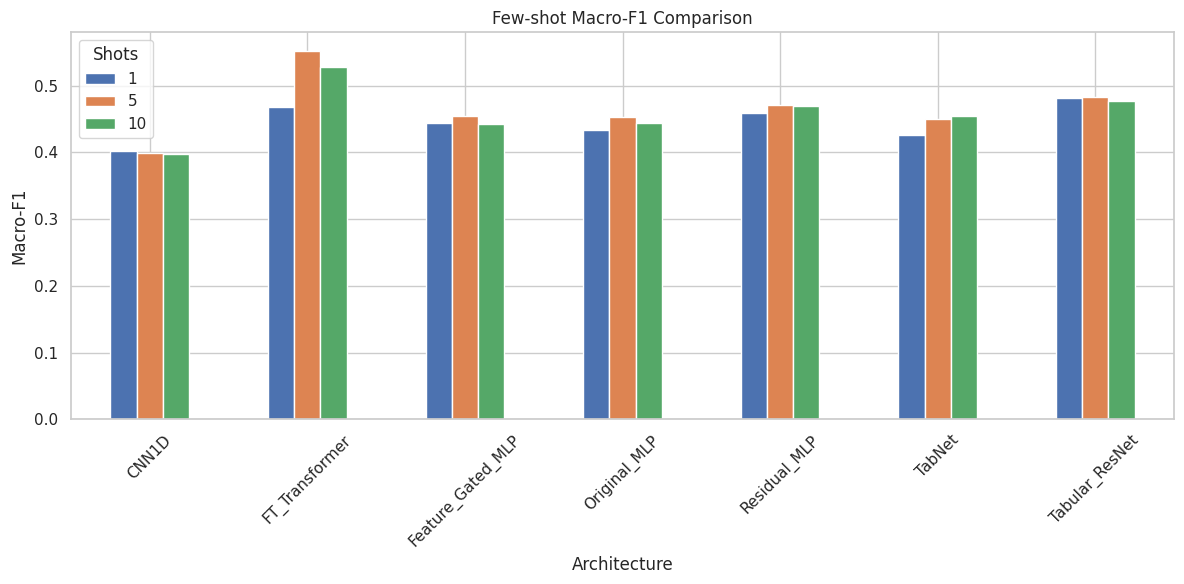

In [64]:
import matplotlib.pyplot as plt


# ============================================================
# 8.3 Macro-F1 Visualization
# ============================================================


shot_comparison.plot(
    kind="bar",
    figsize=(12,6)
)


plt.xlabel(
    "Architecture"
)

plt.ylabel(
    "Macro-F1"
)

plt.title(
    "Few-shot Macro-F1 Comparison"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()

In [65]:
best_model_name = architecture_ranking.index[0]

print(
    "Best Model:",
    best_model_name
)

Best Model: FT_Transformer


In [66]:
best_model = final_models[
    best_model_name
]

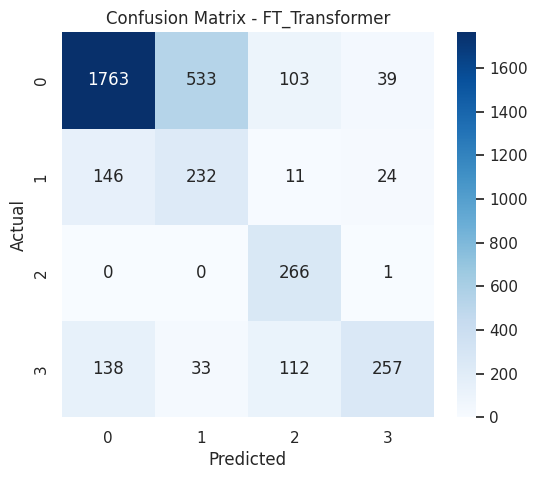

In [67]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# ============================================================
# 8.4 Confusion Matrix
# ============================================================


true, pred = few_shot_eval(

    best_model,

    X_test,

    y_test,

    groups_test,

    SEEN_CLASSES,

    NOVEL_CLASS,

    k_shot=10,

    seed=0

)


cm = confusion_matrix(
    true,
    pred,
    labels=[0,1,2,3]
)


# print(cm)

plt.figure(
    figsize=(6,5)
)


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)


plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)


plt.show()

In [68]:
# ============================================================
# 8.5 Support Diversity Ablation
# ============================================================


support_ablation = (

    paired_results

    .groupby(
        ["Model","Method"]
    )
    [
        [
            "Macro_F1",
            "Legitimate_Recall"
        ]
    ]

    .mean()

)


print(
    support_ablation.round(4)
)

                                   Macro_F1  Legitimate_Recall
Model             Method                                      
CNN1D             Multi_Aircraft     0.7512             0.6860
                  Single_Aircraft    0.6525             0.5096
FT_Transformer    Multi_Aircraft     0.8340             0.6968
                  Single_Aircraft    0.7548             0.6437
Feature_Gated_MLP Multi_Aircraft     0.7596             0.6292
                  Single_Aircraft    0.7289             0.6237
Original_MLP      Multi_Aircraft     0.7841             0.6359
                  Single_Aircraft    0.7171             0.6501
Residual_MLP      Multi_Aircraft     0.7772             0.6341
                  Single_Aircraft    0.7067             0.5865
TabNet            Multi_Aircraft     0.7261             0.4228
                  Single_Aircraft    0.6244             0.4557
Tabular_ResNet    Multi_Aircraft     0.7462             0.5926
                  Single_Aircraft    0.6590            

In [69]:
# Difference between multi-aircraft and single-aircraft support


for metric in [
    "Macro_F1",
    "Legitimate_Recall"
]:

    pivot = paired_results.pivot_table(

        index="Model",

        columns="Method",

        values=metric,

        aggfunc="mean"

    )


    pivot["Improvement"] = (
        pivot["Multi_Aircraft"]
        -
        pivot["Single_Aircraft"]
    )


    print(
        "\n",
        metric
    )

    print(
        pivot.round(4)
    )


 Macro_F1
Method             Multi_Aircraft  Single_Aircraft  Improvement
Model                                                          
CNN1D                      0.7512           0.6525       0.0987
FT_Transformer             0.8340           0.7548       0.0791
Feature_Gated_MLP          0.7596           0.7289       0.0307
Original_MLP               0.7841           0.7171       0.0670
Residual_MLP               0.7772           0.7067       0.0705
TabNet                     0.7261           0.6244       0.1017
Tabular_ResNet             0.7462           0.6590       0.0872

 Legitimate_Recall
Method             Multi_Aircraft  Single_Aircraft  Improvement
Model                                                          
CNN1D                      0.6860           0.5096       0.1764
FT_Transformer             0.6968           0.6437       0.0531
Feature_Gated_MLP          0.6292           0.6237       0.0055
Original_MLP               0.6359           0.6501      -0.0142
Residual_

In [70]:
# ============================================================
# 8.6 Final Results Export
# ============================================================


final_results_summary = (

    final_results_df

    .groupby(
        ["Model","Shots"]
    )
    [
        [
            "Accuracy",
            "Macro_F1",
            "Novel_Recall",
            "Legitimate_Recall"
        ]
    ]

    .mean()

)


final_results_summary.to_csv(
    "Final_Research_Result_Table.csv"
)


architecture_ranking.to_csv(
    "Architecture_Ranking.csv"
)


print(
    "Final analysis files saved."
)

Final analysis files saved.


# ==============================================================================
## Zero-Shot Learning: classifying the unseen class with **zero** labeled examples


In [71]:
ATTRIBUTES = {
    0: [0, 0, 0, 0, 0],   # legitimate
    1: [1, 0, 0, 0, 1],   # path modification
    2: [1, 1, 1, 1, 0],   # ghost aircraft injection
    3: [0, 1, 0, 0, 1],   # velocity drift  <-- NOVEL, used only as an attribute vector below
}

encoder.eval()
with torch.no_grad():
    z_train = encoder(torch.tensor(X_train, dtype=torch.float32)).numpy()
    z_test  = encoder(torch.tensor(X_test,  dtype=torch.float32)).numpy()

centroids_seen = np.stack([z_train[y_train == c].mean(0) for c in SEEN_CLASSES])
A_seen = np.array([ATTRIBUTES[c] for c in SEEN_CLASSES])

# Linear compatibility model: attribute vector -> embedding centroid
compat_model = Ridge(alpha=1.0).fit(A_seen, centroids_seen)

# Predict the novel class's prototype directly from its attribute vector (ZERO labeled examples)
proto_novel_zeroshot = compat_model.predict(np.array([ATTRIBUTES[NOVEL_CLASS]]))[0]

all_classes = SEEN_CLASSES + [NOVEL_CLASS]
zeroshot_protos = np.vstack([centroids_seen, proto_novel_zeroshot])

dists = np.linalg.norm(z_test[:, None, :] - zeroshot_protos[None, :, :], axis=2)
pred_zeroshot = np.array(all_classes)[dists.argmin(1)]

print(f"Zero-shot accuracy (0 labeled examples of class {NOVEL_CLASS}): {accuracy_score(y_test, pred_zeroshot):.3f}")
print(f"Zero-shot macro-F1: {f1_score(y_test, pred_zeroshot, average='macro'):.3f}")
print(classification_report(y_test, pred_zeroshot, target_names=[label_names[c] for c in [0,1,2,3]], digits=3))


Zero-shot accuracy (0 labeled examples of class 3): 0.633
Zero-shot macro-F1: 0.559
                   precision    recall  f1-score   support

       Legitimate      0.815     0.671     0.736      2582
Path modification      0.343     0.384     0.362       518
   Ghost aircraft      0.659     0.991     0.791       534
   Velocity drift      0.320     0.382     0.348       633

         accuracy                          0.633      4267
        macro avg      0.534     0.607     0.559      4267
     weighted avg      0.665     0.633     0.640      4267



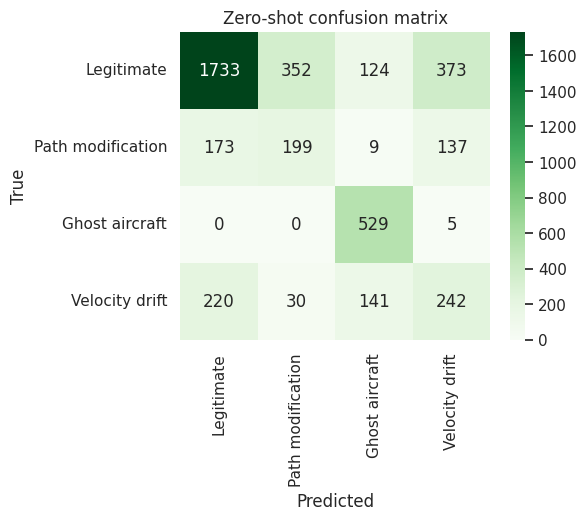

In [72]:
cm = confusion_matrix(y_test, pred_zeroshot, labels=[0,1,2,3])
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=[label_names[c] for c in [0,1,2,3]],
            yticklabels=[label_names[c] for c in [0,1,2,3]], ax=ax)
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title('Zero-shot confusion matrix')
plt.show()
